# DASCM 2026 — Dataset 3
# E-Commerce Sales & Customer Insights Dataset
## Exploratory Data Analysis for `Shipping Fee`

**Project objective:** Understand the supplied e-commerce sales/customer dataset, identify relevant predictors of `Shipping Fee`, investigate each variable and their relationships, detect data-quality issues/outliers, and develop evidence-based brainstorming hypotheses.

---

## 1. Analytical task

The project asks us to predict **`Shipping Fee`** from:

- product category,
- unit price,
- quantity,
- region,
- customer attributes,
- order characteristics.

The project instruction also states:

> **Exclude `Total Price` if it directly embeds the shipping fee.**

The supplied dataset is audited below rather than making that decision from assumption.

### EDA structure

This notebook follows the class workflow:

1. Understand the big picture of the dataset
2. Understand each variable
3. Understand relationships among variables
4. Detect missing values and outliers
5. Use statistical and graphical approaches
6. Brainstorm findings, hypotheses, and questions
7. Support methodological discussion with external references

### Important provenance limitation

The supplied CSV contains the observations and column names but does not include a publisher, original URL, collection protocol, sampling frame, survey/sensor description, or source documentation. Therefore, this notebook **does not invent a source or collection story**. Where the supplied data do not support a claim, the limitation is stated explicitly.


## 2. What is this dataset about?

Based on the supplied columns, the dataset represents **e-commerce orders containing customer, product, pricing, quantity, region, fulfillment-status, and order-date information**.

Each row represents an order-level observation with:

- a customer identifier,
- customer gender and age,
- a geographic region,
- a purchased product and product category,
- unit price and quantity,
- total order price,
- shipping fee,
- shipping status,
- order date.

The analytical question is:

> **Can the shipping fee be understood and eventually predicted from information about the product, order size/value, customer characteristics, geographic region, and order timing?**

The supplied CSV contains **1,000 observations and 12 columns**.

### Target

`Shipping Fee` is the continuous numerical target.

### Leakage / target-embedding check

The project specifically warns about `Total Price`. The supplied data are tested to determine whether:

`Total Price = Unit Price × Quantity`

If that equality holds, `Total Price` is a deterministic order-value variable rather than a field that embeds the shipping fee. In that case, it does **not** directly contain the target, although it is mathematically redundant with `Unit Price` and `Quantity`.

The notebook therefore:
- audits the relationship explicitly;
- does not silently exclude `Total Price`;
- discusses its redundancy and modeling implications separately.


## 3. Data collection and provenance assessment

### What is supported by the supplied file?

The file contains 1,000 order observations with an `Order Date` field. The dates can be parsed and summarized to understand the temporal coverage of the supplied sample.

### What is not supported by the supplied file?

The CSV does not document:

- the original data publisher;
- whether the data are real, simulated, or educationally generated;
- the e-commerce platform;
- the order sampling procedure;
- how shipping fees were calculated;
- whether regions correspond to a particular country;
- the business rules behind shipping status.

Accordingly, this notebook does not claim that the dataset came from a particular website, Kaggle, retailer, or logistics provider.

### Analytical implication

The EDA can establish patterns **within the supplied sample**. It cannot by itself establish that the same relationships hold for an external e-commerce population.


## 4. Data dictionary

| Column | Role / type | Description |
|---|---|---|
| `Customer ID` | Identifier / categorical | Customer identifier associated with the order. Useful for descriptive customer-level analysis, but should be treated carefully as an identifier in prediction. |
| `Gender` | Categorical predictor | Customer gender category recorded in the order data. |
| `Region` | Categorical predictor | Geographic region associated with the customer/order. |
| `Age` | Numerical predictor | Customer age. |
| `Product Name` | Categorical predictor | Purchased product name. |
| `Category` | Categorical predictor | Product category. |
| `Unit Price` | Numerical predictor | Price of one unit of the purchased product. |
| `Quantity` | Numerical predictor | Number of units ordered. |
| `Total Price` | Numerical order characteristic | Total product value. The supplied data are audited to determine whether it equals `Unit Price × Quantity`. |
| `Shipping Fee` | **TARGET** | Continuous shipping charge to be predicted. |
| `Shipping Status` | Fulfillment-status variable | Order/shipping fulfillment state. Useful for descriptive analysis, but it is not an order characteristic that should normally be assumed available when the shipping fee is quoted. |
| `Order Date` | Datetime / order characteristic | Date on which the order was recorded. Used to derive temporal features. |

### Relevant variables

For the stated task, the primary relevant predictors are:

- `Category`
- `Product Name`
- `Unit Price`
- `Quantity`
- `Region`
- `Gender`
- `Age`
- `Total Price` — retained after the explicit leakage audit if it does not embed shipping fee
- `Order Date` → month/day-of-week/other temporal features

`Customer ID` is analyzed descriptively but should not be treated as a meaningful numeric predictor.

`Shipping Status` is inspected descriptively but excluded from the primary pre-shipping predictor set because it describes fulfillment state rather than a customer/order characteristic available when the shipping fee is determined.

`Shipping Fee` is the target.


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pandas.plotting import parallel_coordinates

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

BASE_DIR = Path.cwd()
DATA_PATH = Path("../MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/realistic_e_commerce_sales_data.csv")
PLOT_DIR = BASE_DIR / "plots-4"
PLOT_DIR.mkdir(exist_ok=True)

TARGET = "Shipping Fee"

def save_plot(name):
    path = PLOT_DIR / f"{name}.png"
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved: {path}")

def show_save(name):
    save_plot(name)
    plt.show()


In [2]:
# Load the supplied CSV without modifying it
df = pd.read_csv(DATA_PATH)

print(f"Dataset: {DATA_PATH.name}")
print(f"Shape: {df.shape}")
display(df.head())


Dataset: realistic_e_commerce_sales_data.csv
Shape: (1000, 12)


,Customer ID,Gender,Region,Age,Product Name,Category,Unit Price,Quantity,Total Price,Shipping Fee,Shipping Status,Order Date
0,CUST0268,Male,North,NaN,Monitor,Electronics,300.0,5,1500,13.31,Returned,2023-12-08
1,CUST0046,Male,West,22.0,Headphones,Accessories,100.0,2,200,6.93,In Transit,2023-04-09
2,CUST0169,Female,South,54.0,Monitor,Electronics,300.0,1,300,11.31,Returned,2023-08-28
3,CUST0002,Male,North,23.0,Headphones,Accessories,100.0,5,500,12.22,Delivered,2023-01-18
4,CUST0173,Female,South,NaN,Laptop,Electronics,1500.0,3,4500,5.40,Delivered,2023-01-19


# Part A — Understand the big picture

## 5. Dataset dimensions and structural profile


In [3]:
print("Rows:", f"{len(df):,}")
print("Columns:", df.shape[1])
print("Complete duplicate rows:", df.duplicated().sum())
print("Unique customers:", df["Customer ID"].nunique())
print("Unique products:", df["Product Name"].nunique())
print("Unique categories:", df["Category"].nunique())
print("Unique regions:", df["Region"].nunique(dropna=True))

display(pd.DataFrame({
    "Metric": [
        "Rows", "Columns", "Complete duplicate rows",
        "Unique customers", "Unique products", "Unique categories",
        "Unique non-null regions"
    ],
    "Value": [
        len(df), df.shape[1], df.duplicated().sum(),
        df["Customer ID"].nunique(), df["Product Name"].nunique(),
        df["Category"].nunique(), df["Region"].nunique(dropna=True)
    ]
}))


Rows: 1,000
Columns: 12
Complete duplicate rows: 0
Unique customers: 292
Unique products: 7
Unique categories: 3
Unique regions: 4


,Metric,Value
0,Rows,1000
1,Columns,12
2,Complete duplicate rows,0
3,Unique customers,292
4,Unique products,7
5,Unique categories,3
6,Unique non-null regions,4


In [4]:
# Parse dates and inspect temporal coverage
df["Order Date Parsed"] = pd.to_datetime(df["Order Date"], errors="coerce")

print("Earliest order date:", df["Order Date Parsed"].min())
print("Latest order date:", df["Order Date Parsed"].max())
print("Invalid order dates:", df["Order Date Parsed"].isna().sum())

display(df["Order Date Parsed"].describe().to_frame("value"))


Earliest order date: 2023-01-01 00:00:00
Latest order date: 2024-01-03 00:00:00
Invalid order dates: 0


,value
count,1000
mean,2023-07-07 19:30:43.200000
min,2023-01-01 00:00:00
25%,2023-04-08 00:00:00
50%,2023-07-12 12:00:00
75%,2023-10-12 18:00:00
max,2024-01-03 00:00:00


,Shipping Fee
count,1000.000
mean,12.416
std,4.412
min,5.000
25%,8.560
50%,12.315
75%,16.075
max,19.980


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/01_shipping_fee_distribution.png


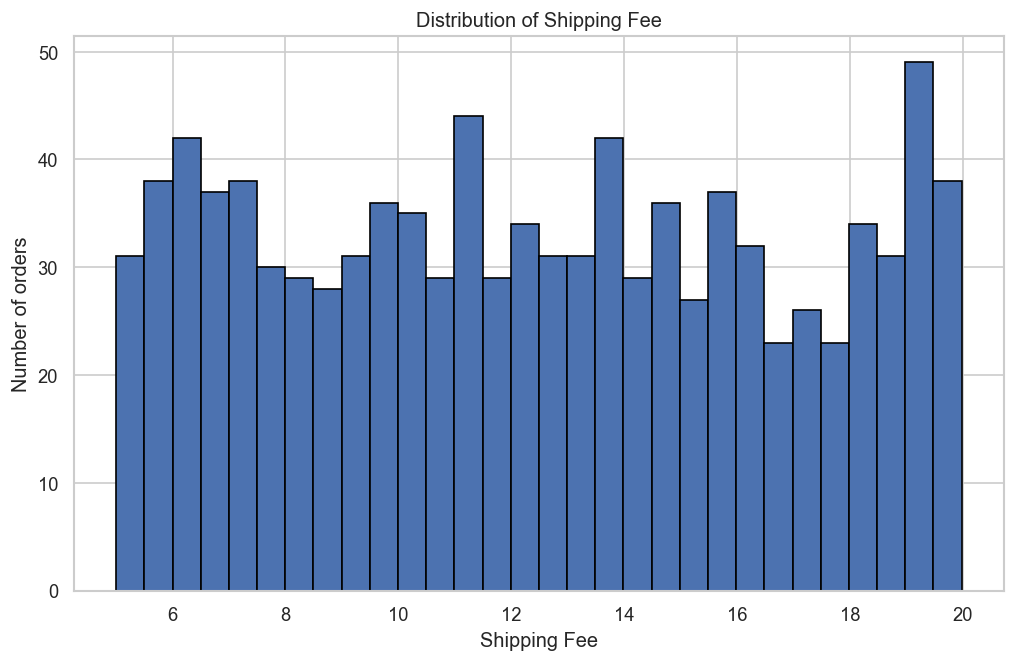

In [5]:
# Target statistical overview
display(df[TARGET].describe().to_frame().round(3))

plt.figure(figsize=(10, 6))
plt.hist(df[TARGET].dropna(), bins=30, edgecolor="black")
plt.xlabel("Shipping Fee")
plt.ylabel("Number of orders")
plt.title("Distribution of Shipping Fee")
show_save("01_shipping_fee_distribution")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/02_shipping_fee_kde.png


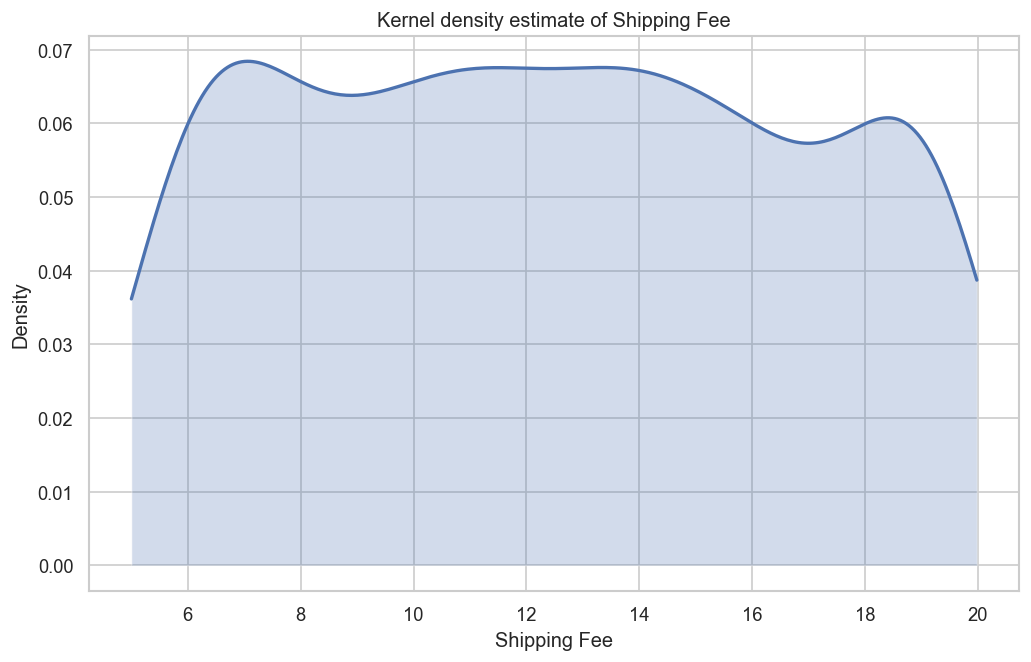

In [6]:
# Target KDE using scipy + matplotlib for compatibility
values = df[TARGET].dropna().to_numpy()
plt.figure(figsize=(10, 6))
if len(values) > 1 and np.std(values) > 0:
    kde = stats.gaussian_kde(values)
    x = np.linspace(values.min(), values.max(), 300)
    plt.plot(x, kde(x), linewidth=2)
    plt.fill_between(x, kde(x), alpha=0.25)
plt.xlabel("Shipping Fee")
plt.ylabel("Density")
plt.title("Kernel density estimate of Shipping Fee")
show_save("02_shipping_fee_kde")


## 6. `Total Price` leakage / embedding audit

The project instruction says to exclude `Total Price` **if it directly embeds the shipping fee**.

The supplied data are checked explicitly.

A deterministic relationship of:

`Total Price = Unit Price × Quantity`

would mean that `Total Price` represents merchandise value, not shipping fee. It would still be redundant with `Unit Price` and `Quantity`, but redundancy is different from target leakage.

If the equality does not hold, the relationship is inspected further rather than making an unsupported assumption.


In [7]:
# Explicit audit of Total Price
expected_total = df["Unit Price"] * df["Quantity"]
difference = df["Total Price"] - expected_total

print("All Total Price values equal Unit Price × Quantity:", np.isclose(difference, 0).all())
print("Maximum absolute difference:", np.abs(difference).max())
print("Number of mismatches:", (np.abs(difference) > 1e-9).sum())

audit_table = df[["Unit Price", "Quantity", "Total Price", "Shipping Fee"]].copy()
audit_table["Expected Total Price"] = expected_total
audit_table["Total Price Difference"] = difference
display(audit_table.head(10))


All Total Price values equal Unit Price × Quantity: False
Maximum absolute difference: 8047.803062433259
Number of mismatches: 20


,Unit Price,Quantity,Total Price,Shipping Fee,Expected Total Price,Total Price Difference
0,300.0,5,1500,13.31,1500.0,0.0
1,100.0,2,200,6.93,200.0,0.0
2,300.0,1,300,11.31,300.0,0.0
3,100.0,5,500,12.22,500.0,0.0
4,1500.0,3,4500,5.40,4500.0,0.0
5,200.0,2,400,11.26,400.0,0.0
6,200.0,1,200,18.38,200.0,0.0
7,50.0,2,100,15.08,100.0,0.0
8,30.0,1,30,8.22,30.0,0.0
9,100.0,3,300,10.70,300.0,0.0


### Leakage decision

In the supplied dataset, `Total Price` is the merchandise/order value and is exactly determined by:

**`Unit Price × Quantity`**

It therefore does **not** directly embed `Shipping Fee`.

However, it is redundant with two retained predictors. The notebook keeps it for EDA because the project explicitly identifies order characteristics as relevant, while clearly flagging the redundancy for the later modeling stage.

A later model should compare:
- `Unit Price` + `Quantity`, versus
- `Total Price`,
rather than blindly using all three without considering multicollinearity/redundancy.


# Part B — Data types and missing values

## 7. Structural data-quality analysis


In [8]:
dtype_table = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": [str(df[c].dtype) for c in df.columns],
    "Non_Null": [df[c].notna().sum() for c in df.columns],
    "Missing": [df[c].isna().sum() for c in df.columns],
    "Missing_%": [df[c].isna().mean()*100 for c in df.columns],
    "Unique": [df[c].nunique(dropna=True) for c in df.columns]
})
display(dtype_table.round(2))


,Column,Data_Type,Non_Null,Missing,Missing_%,Unique
0,Customer ID,object,1000,0,0.0,292
1,Gender,object,1000,0,0.0,2
2,Region,object,950,50,5.0,4
3,Age,float64,900,100,10.0,52
4,Product Name,object,1000,0,0.0,7
5,Category,object,1000,0,0.0,3
6,Unit Price,float64,1000,0,0.0,13
7,Quantity,int64,1000,0,0.0,5
8,Total Price,int64,1000,0,0.0,26
9,Shipping Fee,float64,1000,0,0.0,730


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/03_missing_value_rate.png


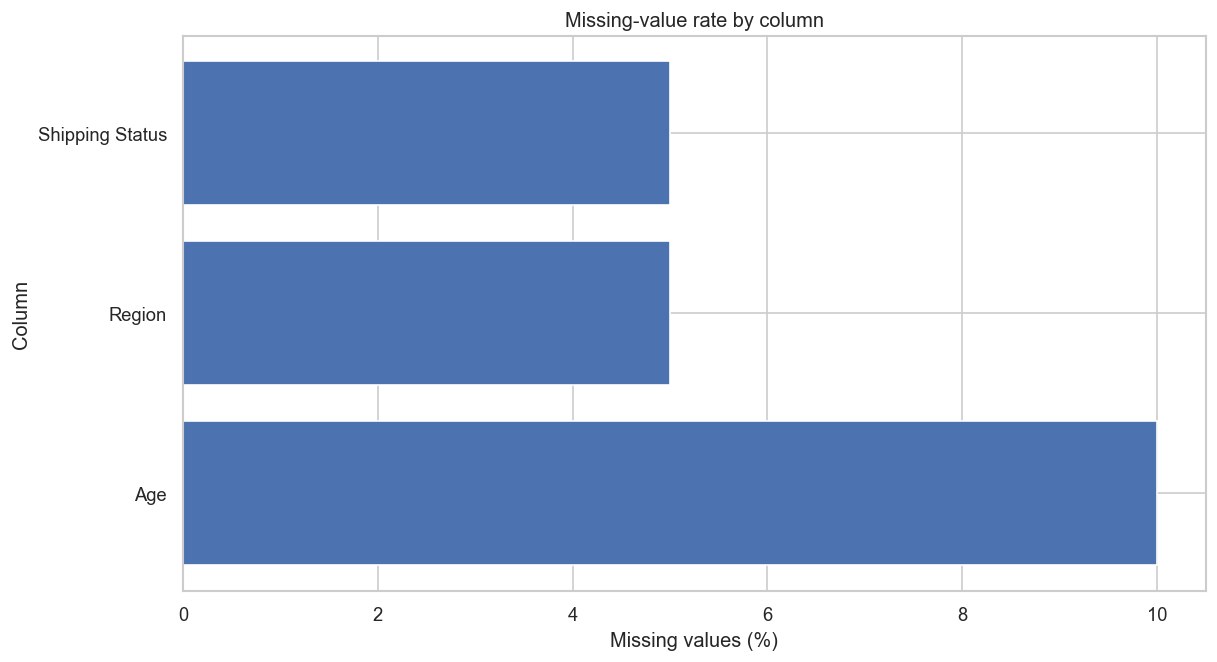

In [9]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = df.isna().mean().sort_values(ascending=False) * 100

plt.figure(figsize=(11, 6))
mask = missing > 0
plt.barh(missing.index[mask].astype(str), missing_pct[mask].values)
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Missing-value rate by column")
show_save("03_missing_value_rate")


### Missingness interpretation

The supplied file contains missing values in `Region`, `Age`, and `Shipping Status`.

For the target task, missing `Region` and `Age` require an explicit preprocessing strategy later. `Shipping Status` is excluded from the primary pre-shipping predictor set, so its missingness does not directly affect the main feature set.

No missing values are silently imputed in this EDA notebook.


# Part C — Understand each variable

## 8. Categorical variables

The main categorical variables are:

- `Gender`
- `Region`
- `Product Name`
- `Category`
- `Shipping Status`

`Customer ID` is treated as an identifier rather than as an ordinary nominal feature.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/04_categorical_distribution_gender.png


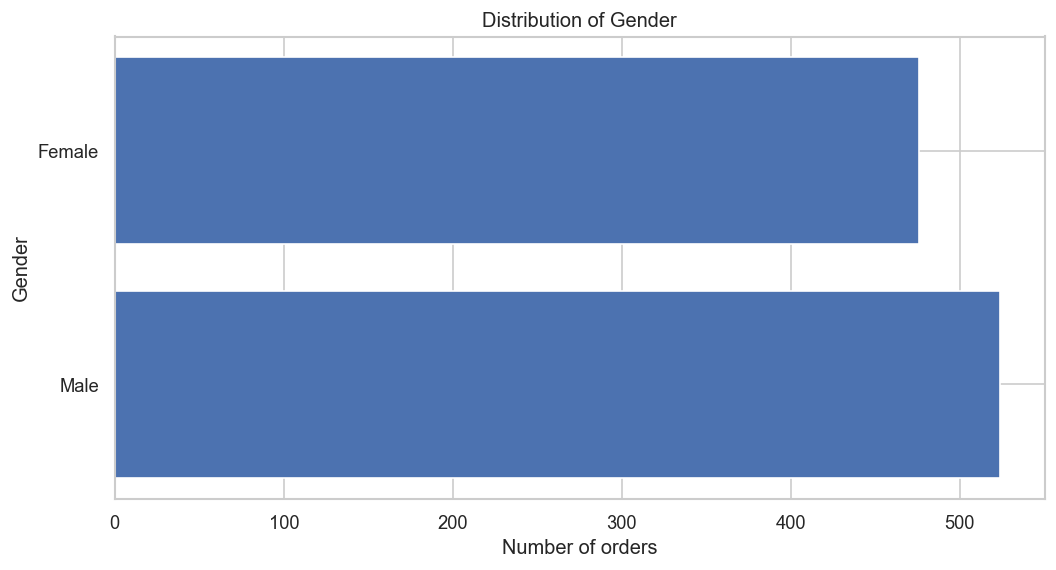

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/04_categorical_distribution_region.png


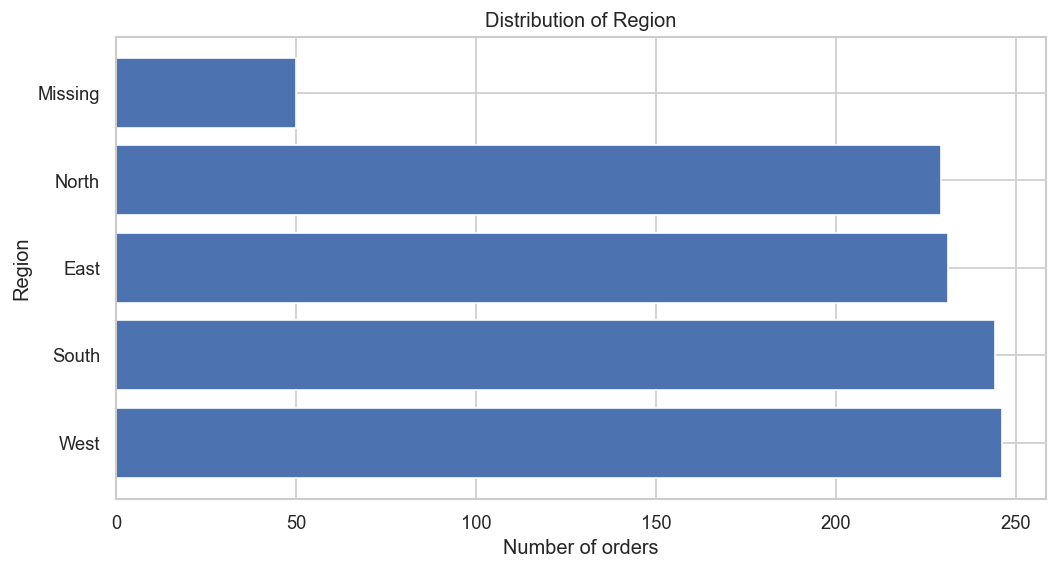

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/04_categorical_distribution_product_name.png


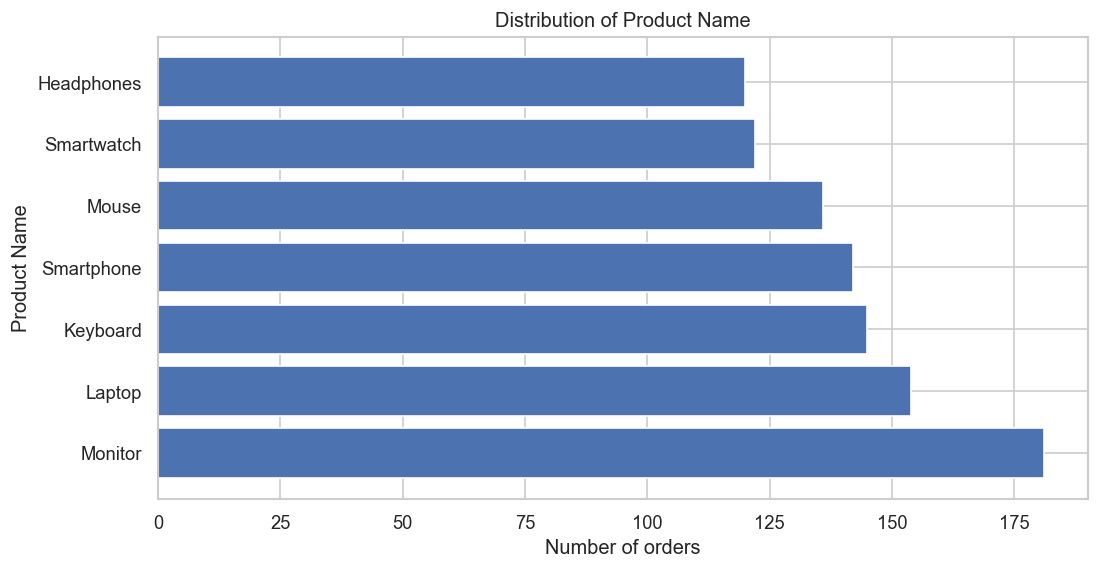

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/04_categorical_distribution_category.png


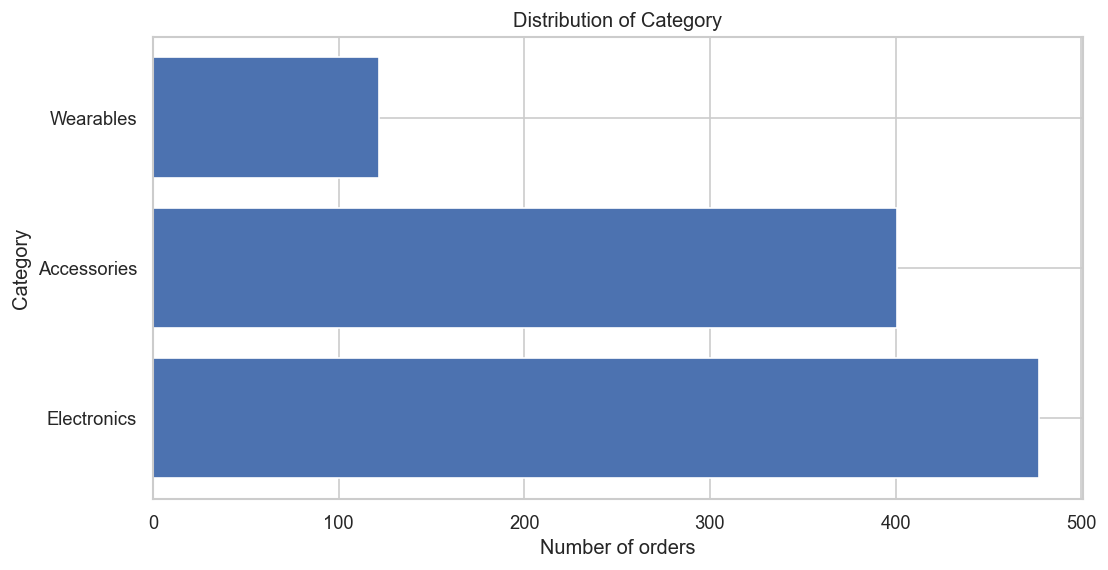

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/04_categorical_distribution_shipping_status.png


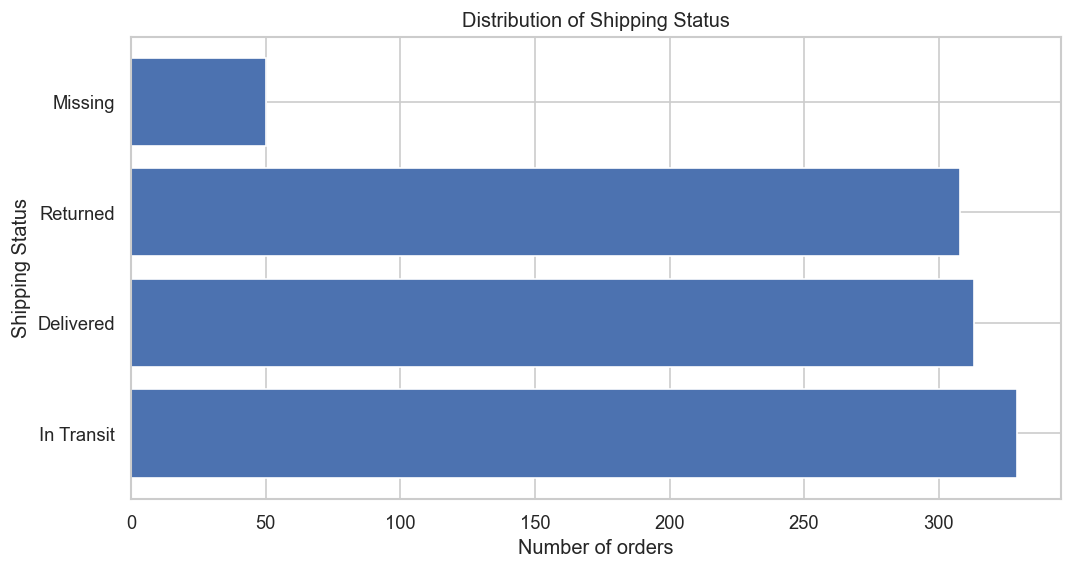

In [10]:
categorical_cols = [
    "Gender", "Region", "Product Name", "Category", "Shipping Status"
]

for col in categorical_cols:
    counts = df[col].fillna("Missing").value_counts()
    plt.figure(figsize=(10, max(5, 0.35*len(counts))))
    plt.barh(counts.index.astype(str), counts.values)
    plt.xlabel("Number of orders")
    plt.ylabel(col)
    plt.title(f"Distribution of {col}")
    show_save(f"04_categorical_distribution_{col.lower().replace(' ', '_')}")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/05_pie_gender.png


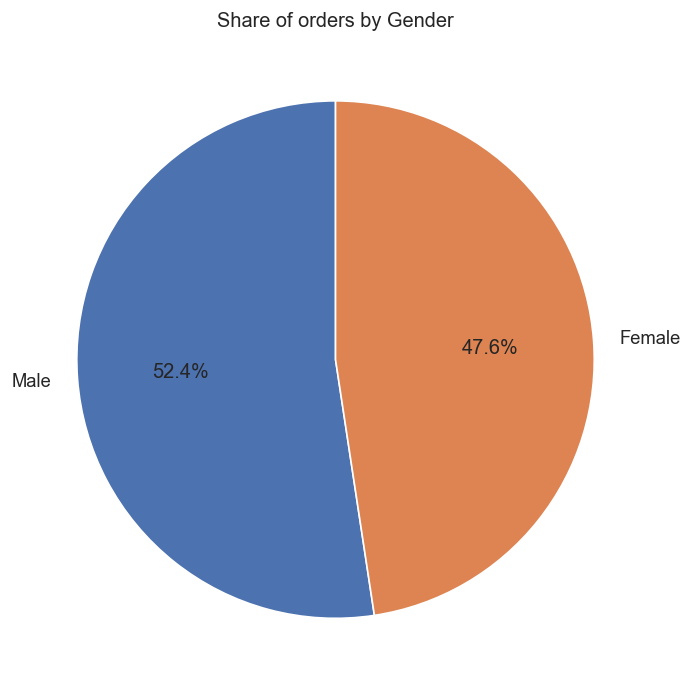

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/05_pie_region.png


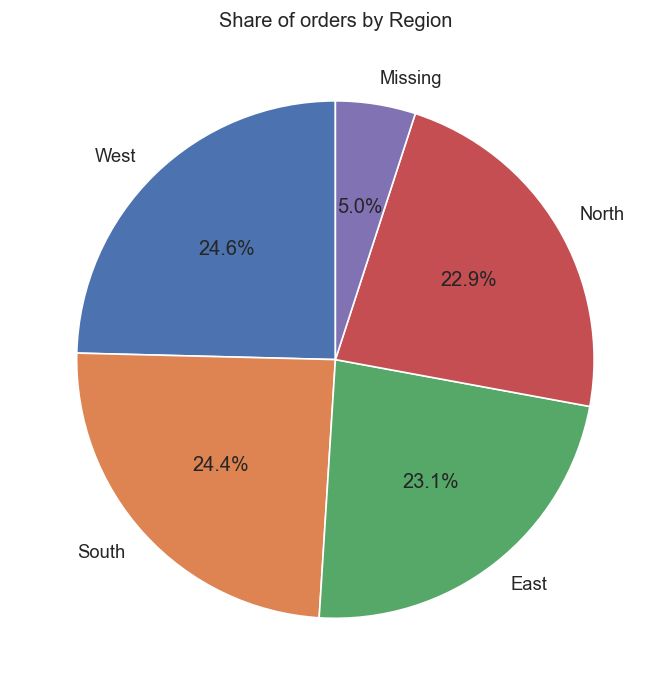

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/05_pie_category.png


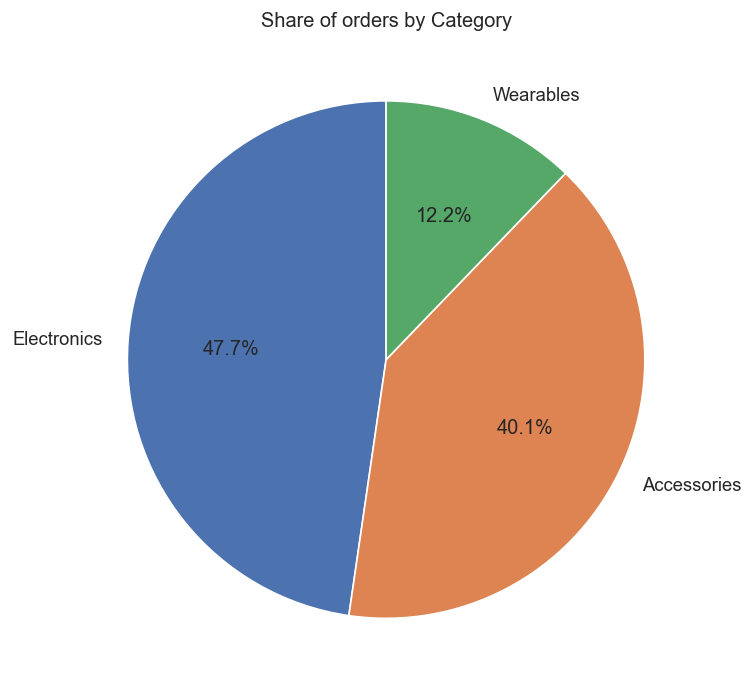

In [11]:
# Pie charts for compact categorical variables
for col in ["Gender", "Region", "Category"]:
    counts = df[col].fillna("Missing").value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
    plt.title(f"Share of orders by {col}")
    show_save(f"05_pie_{col.lower()}")


In [12]:
# Product/category average shipping fee
for col in ["Category", "Product Name", "Region", "Gender"]:
    summary = df.groupby(col, dropna=False)[TARGET].agg(["count", "mean", "median"]).sort_values("mean", ascending=False)
    print(f"\n--- {col} ---")
    display(summary.round(3))



--- Category ---


,count,mean,median
Category,,,
Electronics,477,12.616,12.910
Wearables,122,12.354,12.045
Accessories,401,12.198,11.880



--- Product Name ---


,count,mean,median
Product Name,,,
Smartphone,142,12.885,13.360
Monitor,181,12.764,13.280
Headphones,120,12.532,12.110
Smartwatch,122,12.354,12.045
Laptop,154,12.193,12.365
Keyboard,145,12.117,11.720
Mouse,136,11.991,11.405



--- Region ---


,count,mean,median
Region,,,
North,229,12.549,12.890
West,246,12.414,12.605
South,244,12.399,12.010
NaN,50,12.366,12.335
East,231,12.317,12.220



--- Gender ---


,count,mean,median
Gender,,,
Male,524,12.417,12.300
Female,476,12.415,12.355


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/06_mean_shipping_fee_by_category.png


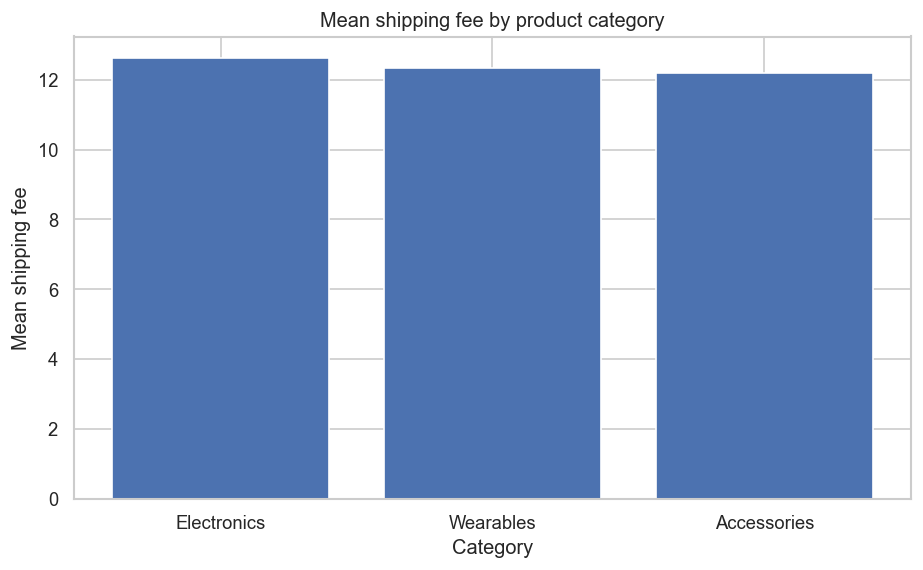

In [13]:
# Average shipping fee by category
cat_fee = df.groupby("Category")[TARGET].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(cat_fee.index, cat_fee.values)
plt.xlabel("Category")
plt.ylabel("Mean shipping fee")
plt.title("Mean shipping fee by product category")
show_save("06_mean_shipping_fee_by_category")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/07_mean_shipping_fee_by_region.png


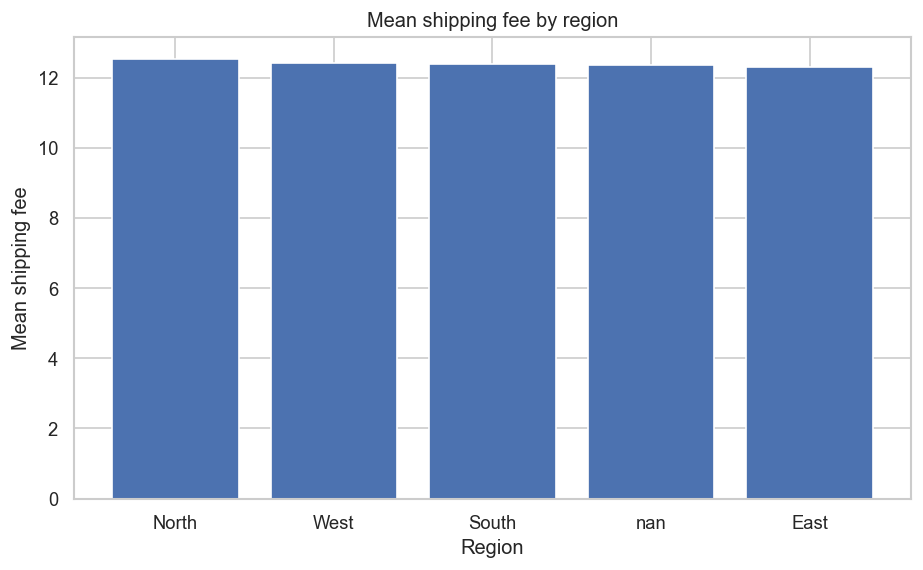

In [14]:
# Mean shipping fee by region
region_fee = df.groupby("Region", dropna=False)[TARGET].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(region_fee.index.astype(str), region_fee.values)
plt.xlabel("Region")
plt.ylabel("Mean shipping fee")
plt.title("Mean shipping fee by region")
show_save("07_mean_shipping_fee_by_region")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/08_mean_shipping_fee_by_gender.png


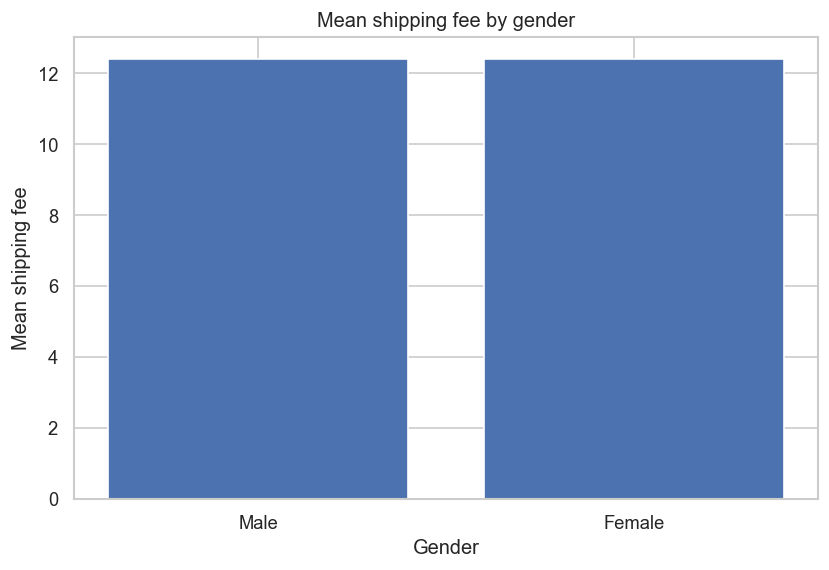

In [15]:
# Mean shipping fee by gender
gender_fee = df.groupby("Gender")[TARGET].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(gender_fee.index, gender_fee.values)
plt.xlabel("Gender")
plt.ylabel("Mean shipping fee")
plt.title("Mean shipping fee by gender")
show_save("08_mean_shipping_fee_by_gender")


## 9. Numerical variables

The numerical variables are:

- `Age`
- `Unit Price`
- `Quantity`
- `Total Price`
- `Shipping Fee` (target)

These are examined using descriptive statistics, histograms/KDE, box plots, and violin plots.


In [16]:
numeric_predictors = ["Age", "Unit Price", "Quantity", "Total Price"]

numeric_summary = df[numeric_predictors + [TARGET]].describe().T
numeric_summary["skewness"] = df[numeric_predictors + [TARGET]].skew()
numeric_summary["missing"] = df[numeric_predictors + [TARGET]].isna().sum()
display(numeric_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,skewness,missing
Age,900.0,46.696,15.011,18.0,35.00,49.000,59.000,69.000,-0.271,100
Unit Price,1000.0,457.704,537.231,30.0,50.00,200.000,800.000,3109.561,1.466,0
Quantity,1000.0,3.008,1.404,1.0,2.00,3.000,4.000,5.000,-0.014,0
Total Price,1000.0,1346.600,1834.038,30.0,200.00,600.000,1500.000,7500.000,1.927,0
Shipping Fee,1000.0,12.416,4.412,5.0,8.56,12.315,16.075,19.980,0.050,0


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/09_numerical_histograms_kde.png


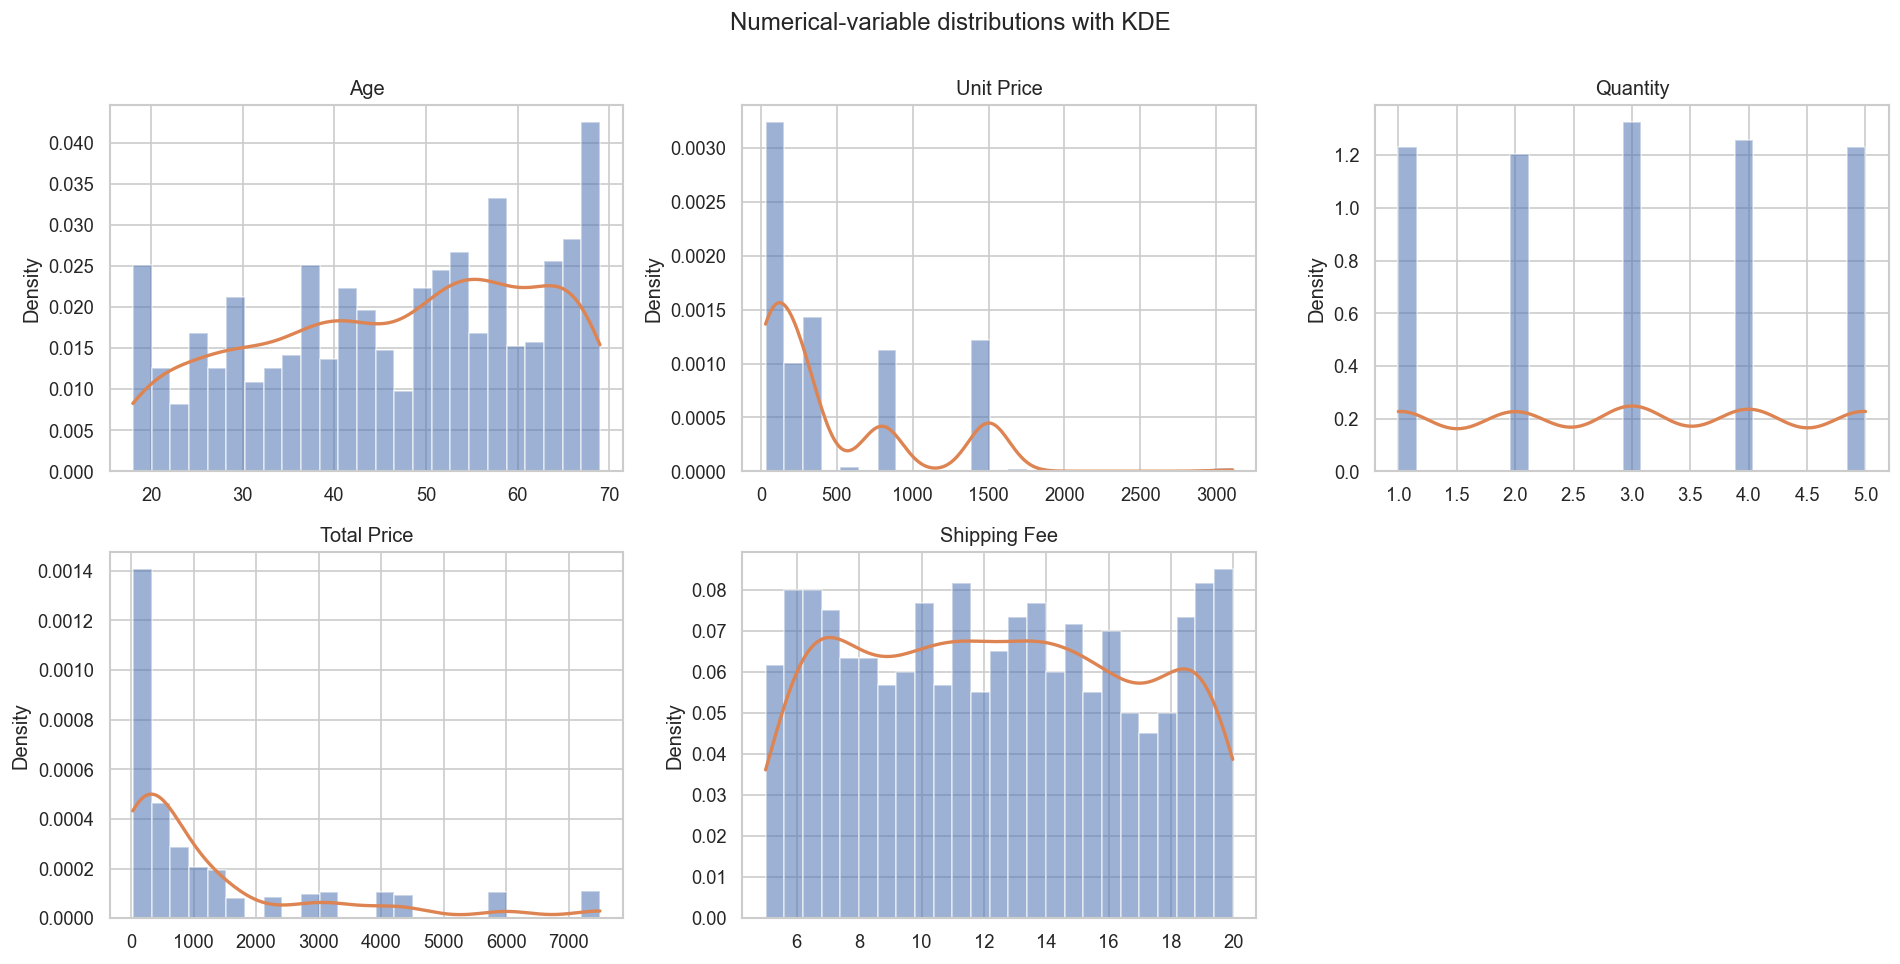

In [17]:
# Histograms + KDE
dist_cols = numeric_predictors + [TARGET]
ncols = 3
nrows = int(np.ceil(len(dist_cols)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4*nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, dist_cols):
    values = df[col].dropna().to_numpy()
    ax.hist(values, bins=25, density=True, alpha=0.55)
    if len(values) > 1 and np.std(values) > 0:
        kde = stats.gaussian_kde(values)
        x = np.linspace(values.min(), values.max(), 250)
        ax.plot(x, kde(x), linewidth=2)
    ax.set_title(col)
    ax.set_ylabel("Density")

for ax in axes[len(dist_cols):]:
    ax.axis("off")

fig.suptitle("Numerical-variable distributions with KDE", y=1.002)
plt.tight_layout()
show_save("09_numerical_histograms_kde")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/10_numerical_boxplots.png


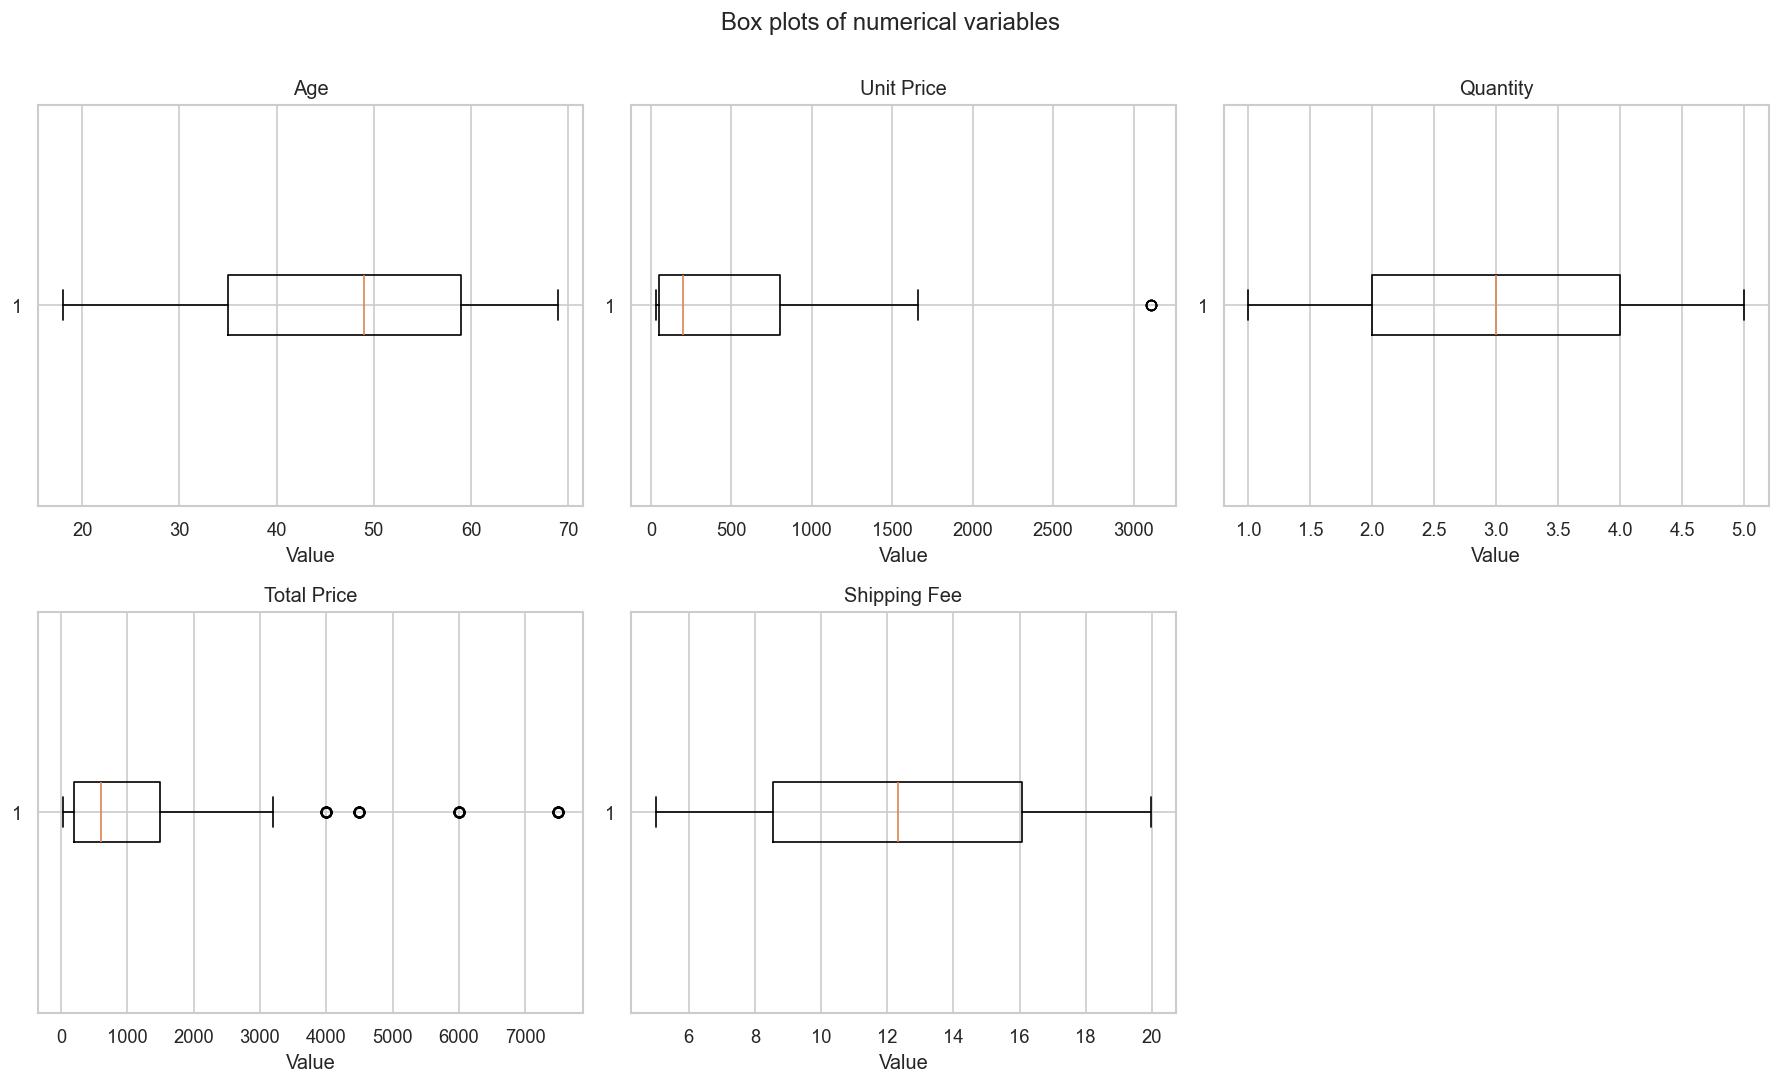

In [18]:
# Box plots
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, col in zip(axes, dist_cols):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(col)
    ax.set_xlabel("Value")

for ax in axes[len(dist_cols):]:
    ax.axis("off")

fig.suptitle("Box plots of numerical variables", y=1.002)
plt.tight_layout()
show_save("10_numerical_boxplots")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/11_violin_predictors_vs_shipping_fee_groups.png


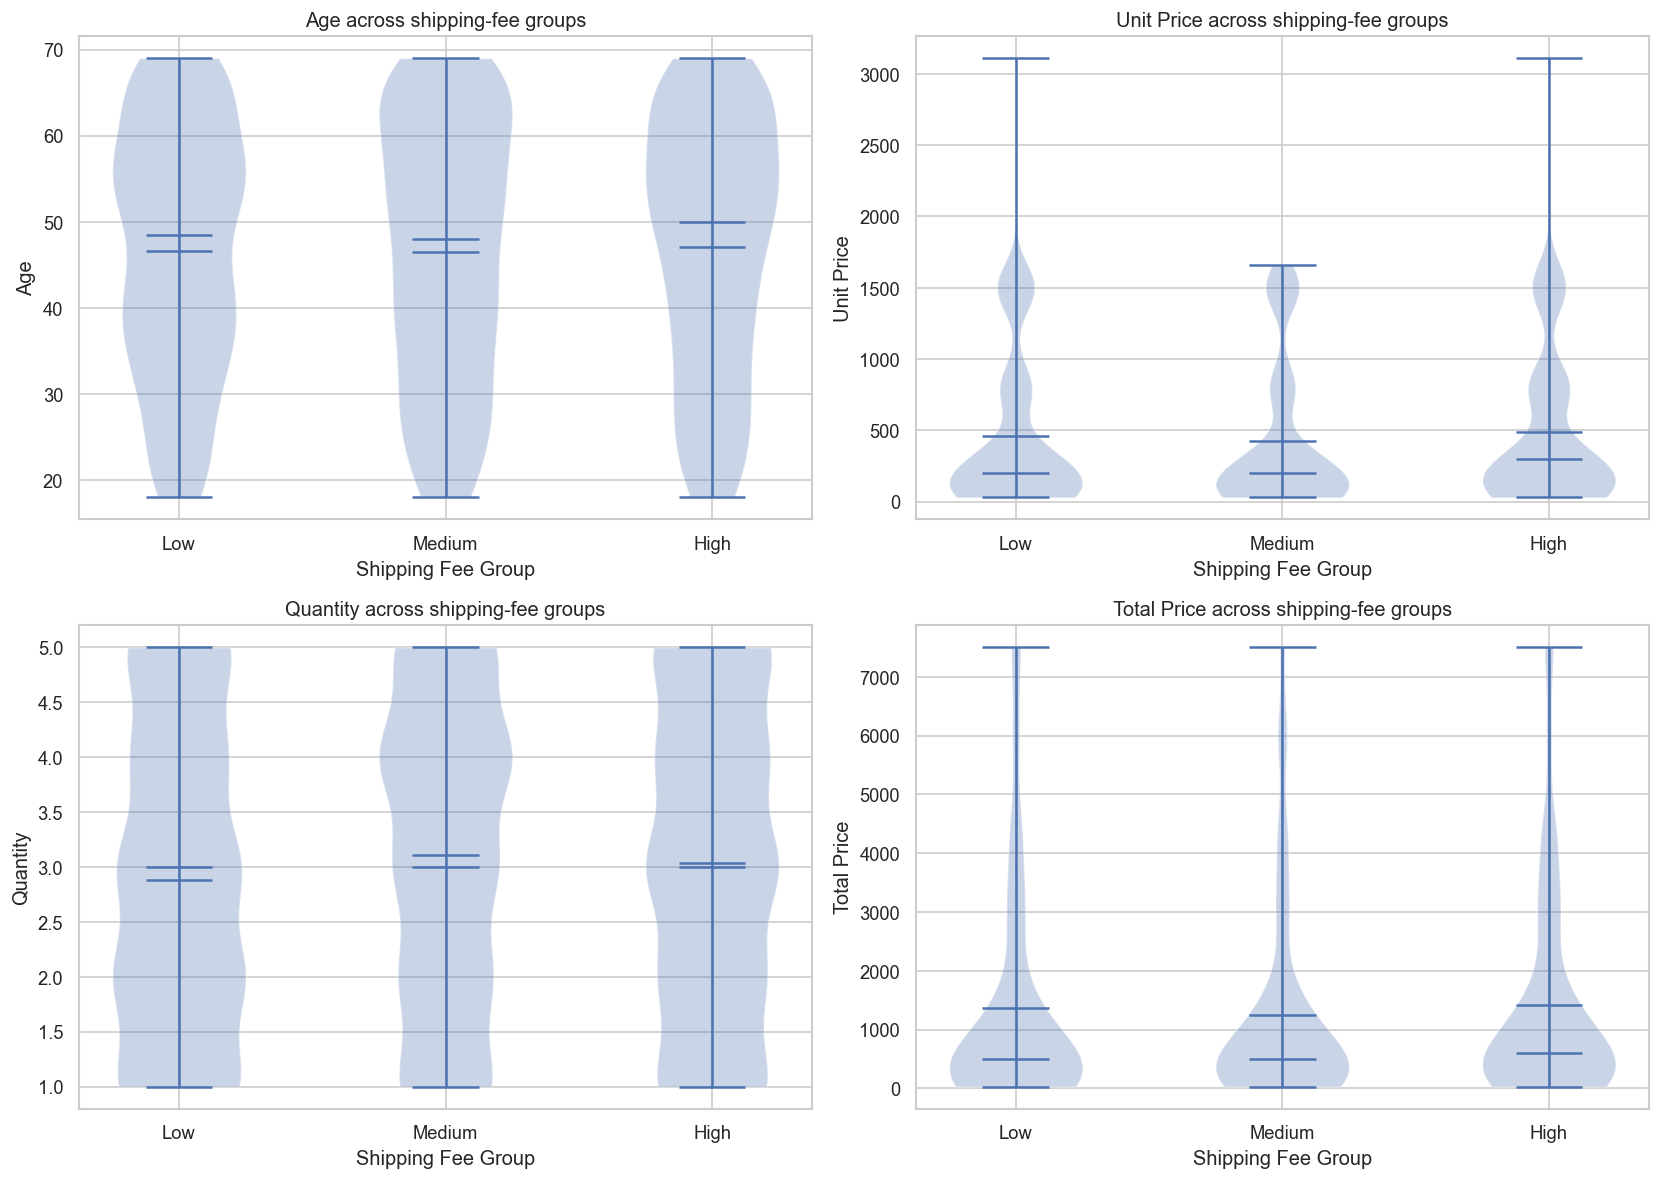

In [19]:
# Violin plots of predictors across low/medium/high shipping-fee groups
violin_cols = ["Age", "Unit Price", "Quantity", "Total Price"]

work = df.copy()
work["Shipping_Fee_Group"] = pd.qcut(
    work[TARGET], q=3, labels=["Low", "Medium", "High"], duplicates="drop"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.ravel(), violin_cols):
    groups = [
        work.loc[work["Shipping_Fee_Group"] == level, col].dropna().to_numpy()
        for level in ["Low", "Medium", "High"]
    ]
    valid = [(level, g) for level, g in zip(["Low", "Medium", "High"], groups) if len(g) > 0]
    ax.violinplot([g for _, g in valid], showmeans=True, showmedians=True)
    ax.set_xticks(range(1, len(valid) + 1))
    ax.set_xticklabels([level for level, _ in valid])
    ax.set_title(f"{col} across shipping-fee groups")
    ax.set_xlabel("Shipping Fee Group")
    ax.set_ylabel(col)

plt.tight_layout()
show_save("11_violin_predictors_vs_shipping_fee_groups")


# Part D — Outlier detection

## 10. IQR-based screening

The 1.5×IQR rule is used to identify observations that are unusual relative to each numerical variable's central distribution.

These observations are **not automatically deleted**. In e-commerce, unusually large quantities or high-value orders can be genuine orders and may be particularly informative for shipping-fee analysis.


In [20]:
outlier_records = []

for col in numeric_predictors + [TARGET]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_records.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower,
        "Upper_Fence": upper,
        "Outlier_Count": int(mask.sum()),
        "Outlier_%": float(mask.mean()*100)
    })

outlier_table = pd.DataFrame(outlier_records).sort_values("Outlier_%", ascending=False)
display(outlier_table.round(3))


,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outlier_Count,Outlier_%
3,Total Price,200.00,1500.000,1300.000,-1750.000,3450.000,124,12.4
1,Unit Price,50.00,800.000,750.000,-1075.000,1925.000,4,0.4
0,Age,35.00,59.000,24.000,-1.000,95.000,0,0.0
2,Quantity,2.00,4.000,2.000,-1.000,7.000,0,0.0
4,Shipping Fee,8.56,16.075,7.515,-2.712,27.347,0,0.0


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/12_iqr_outlier_rates.png


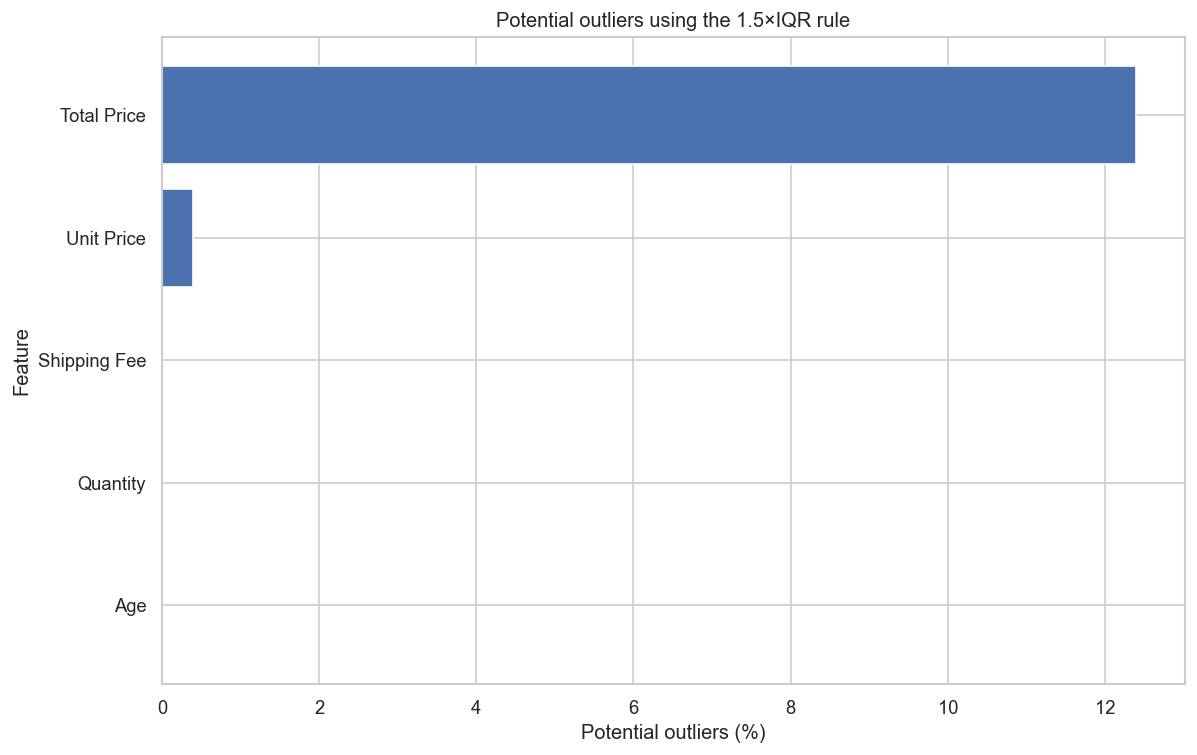

In [21]:
plot_out = outlier_table.sort_values("Outlier_%")

plt.figure(figsize=(11, 7))
plt.barh(plot_out["Feature"], plot_out["Outlier_%"])
plt.xlabel("Potential outliers (%)")
plt.ylabel("Feature")
plt.title("Potential outliers using the 1.5×IQR rule")
show_save("12_iqr_outlier_rates")


In [22]:
# Examine high-value / high-quantity observations without deleting them
display(
    df.nlargest(10, "Total Price")[
        ["Customer ID", "Category", "Product Name", "Unit Price",
         "Quantity", "Total Price", "Shipping Fee", "Region"]
    ]
)


,Customer ID,Category,Product Name,Unit Price,Quantity,Total Price,Shipping Fee,Region
59,CUST0006,Electronics,Laptop,1500.0,5,7500,19.69,South
71,CUST0261,Electronics,Laptop,1500.0,5,7500,15.95,West
79,CUST0269,Electronics,Laptop,1500.0,5,7500,6.53,East
113,CUST0289,Electronics,Laptop,1500.0,5,7500,6.68,West
130,CUST0212,Electronics,Laptop,1500.0,5,7500,10.18,North
139,CUST0091,Electronics,Laptop,1500.0,5,7500,7.58,East
205,CUST0095,Electronics,Laptop,1500.0,5,7500,7.38,East
237,CUST0272,Electronics,Laptop,1500.0,5,7500,9.45,West
293,CUST0204,Electronics,Laptop,1500.0,5,7500,5.02,South
300,CUST0106,Electronics,Laptop,1500.0,5,7500,15.14,North


### Outlier interpretation

A high `Total Price` can result from either a high unit price or a high quantity. Such observations are not automatically errors.

This distinction is important because shipping fees may plausibly vary with package quantity, product type, or order value. A robust modeling approach should therefore test whether these observations represent meaningful shipping-cost regimes rather than simply removing them.


# Part E — Relationships among variables

## 11. Correlation analysis

Pearson correlation is used as a descriptive measure for linear association among numerical variables. Correlation is not evidence of causality and may miss nonlinear patterns.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/13_correlation_heatmap.png


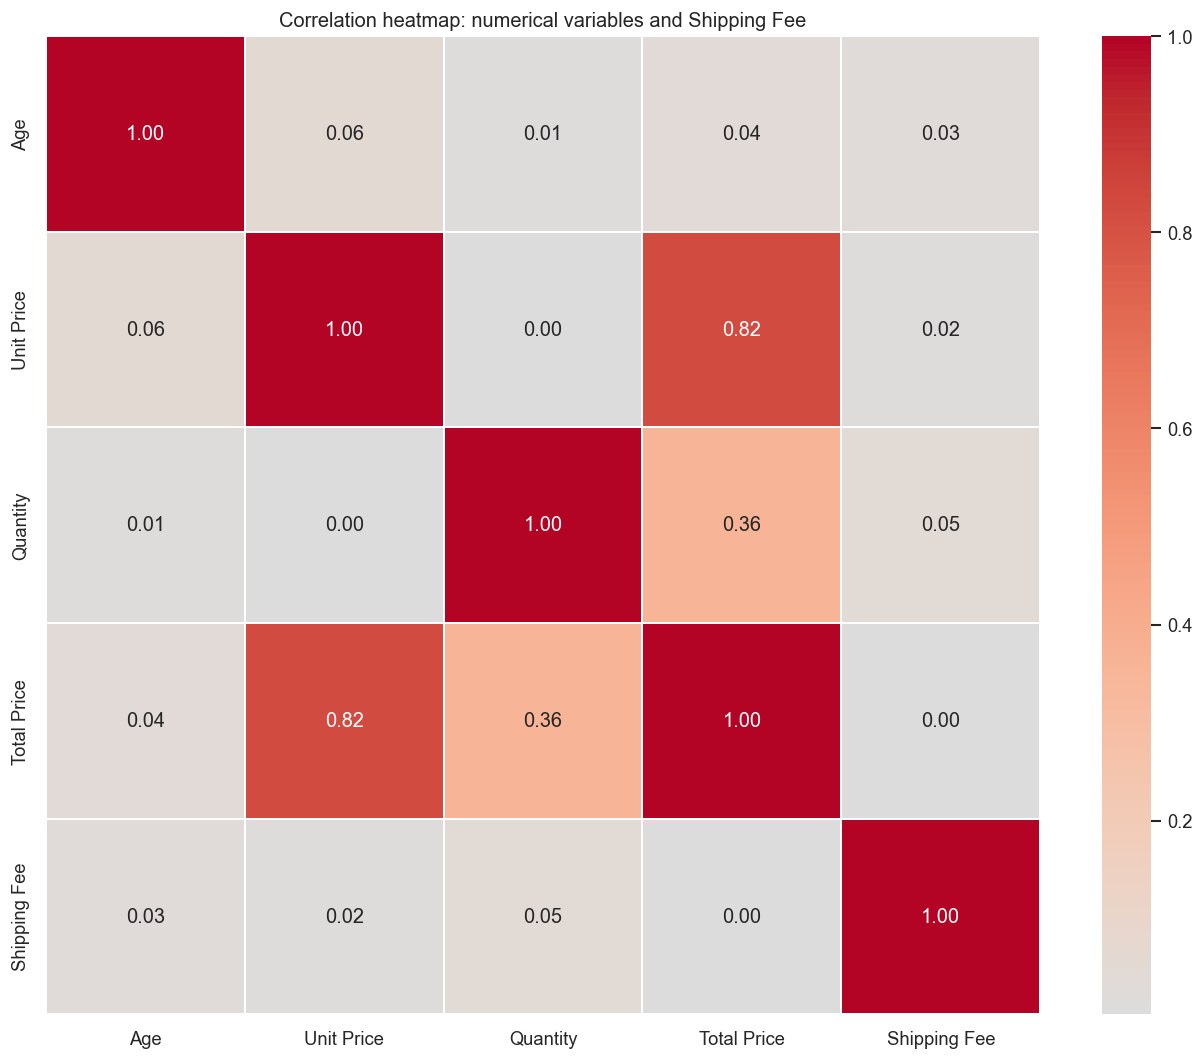

In [23]:
corr_cols = numeric_predictors + [TARGET]
corr = df[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", center=0, cmap="coolwarm", linewidths=0.2)
plt.title("Correlation heatmap: numerical variables and Shipping Fee")
plt.tight_layout()
show_save("13_correlation_heatmap")


In [24]:
target_corr = corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.to_frame("Pearson_r").round(3))


,Pearson_r
Quantity,0.046
Age,0.027
Unit Price,0.017
Total Price,0.003


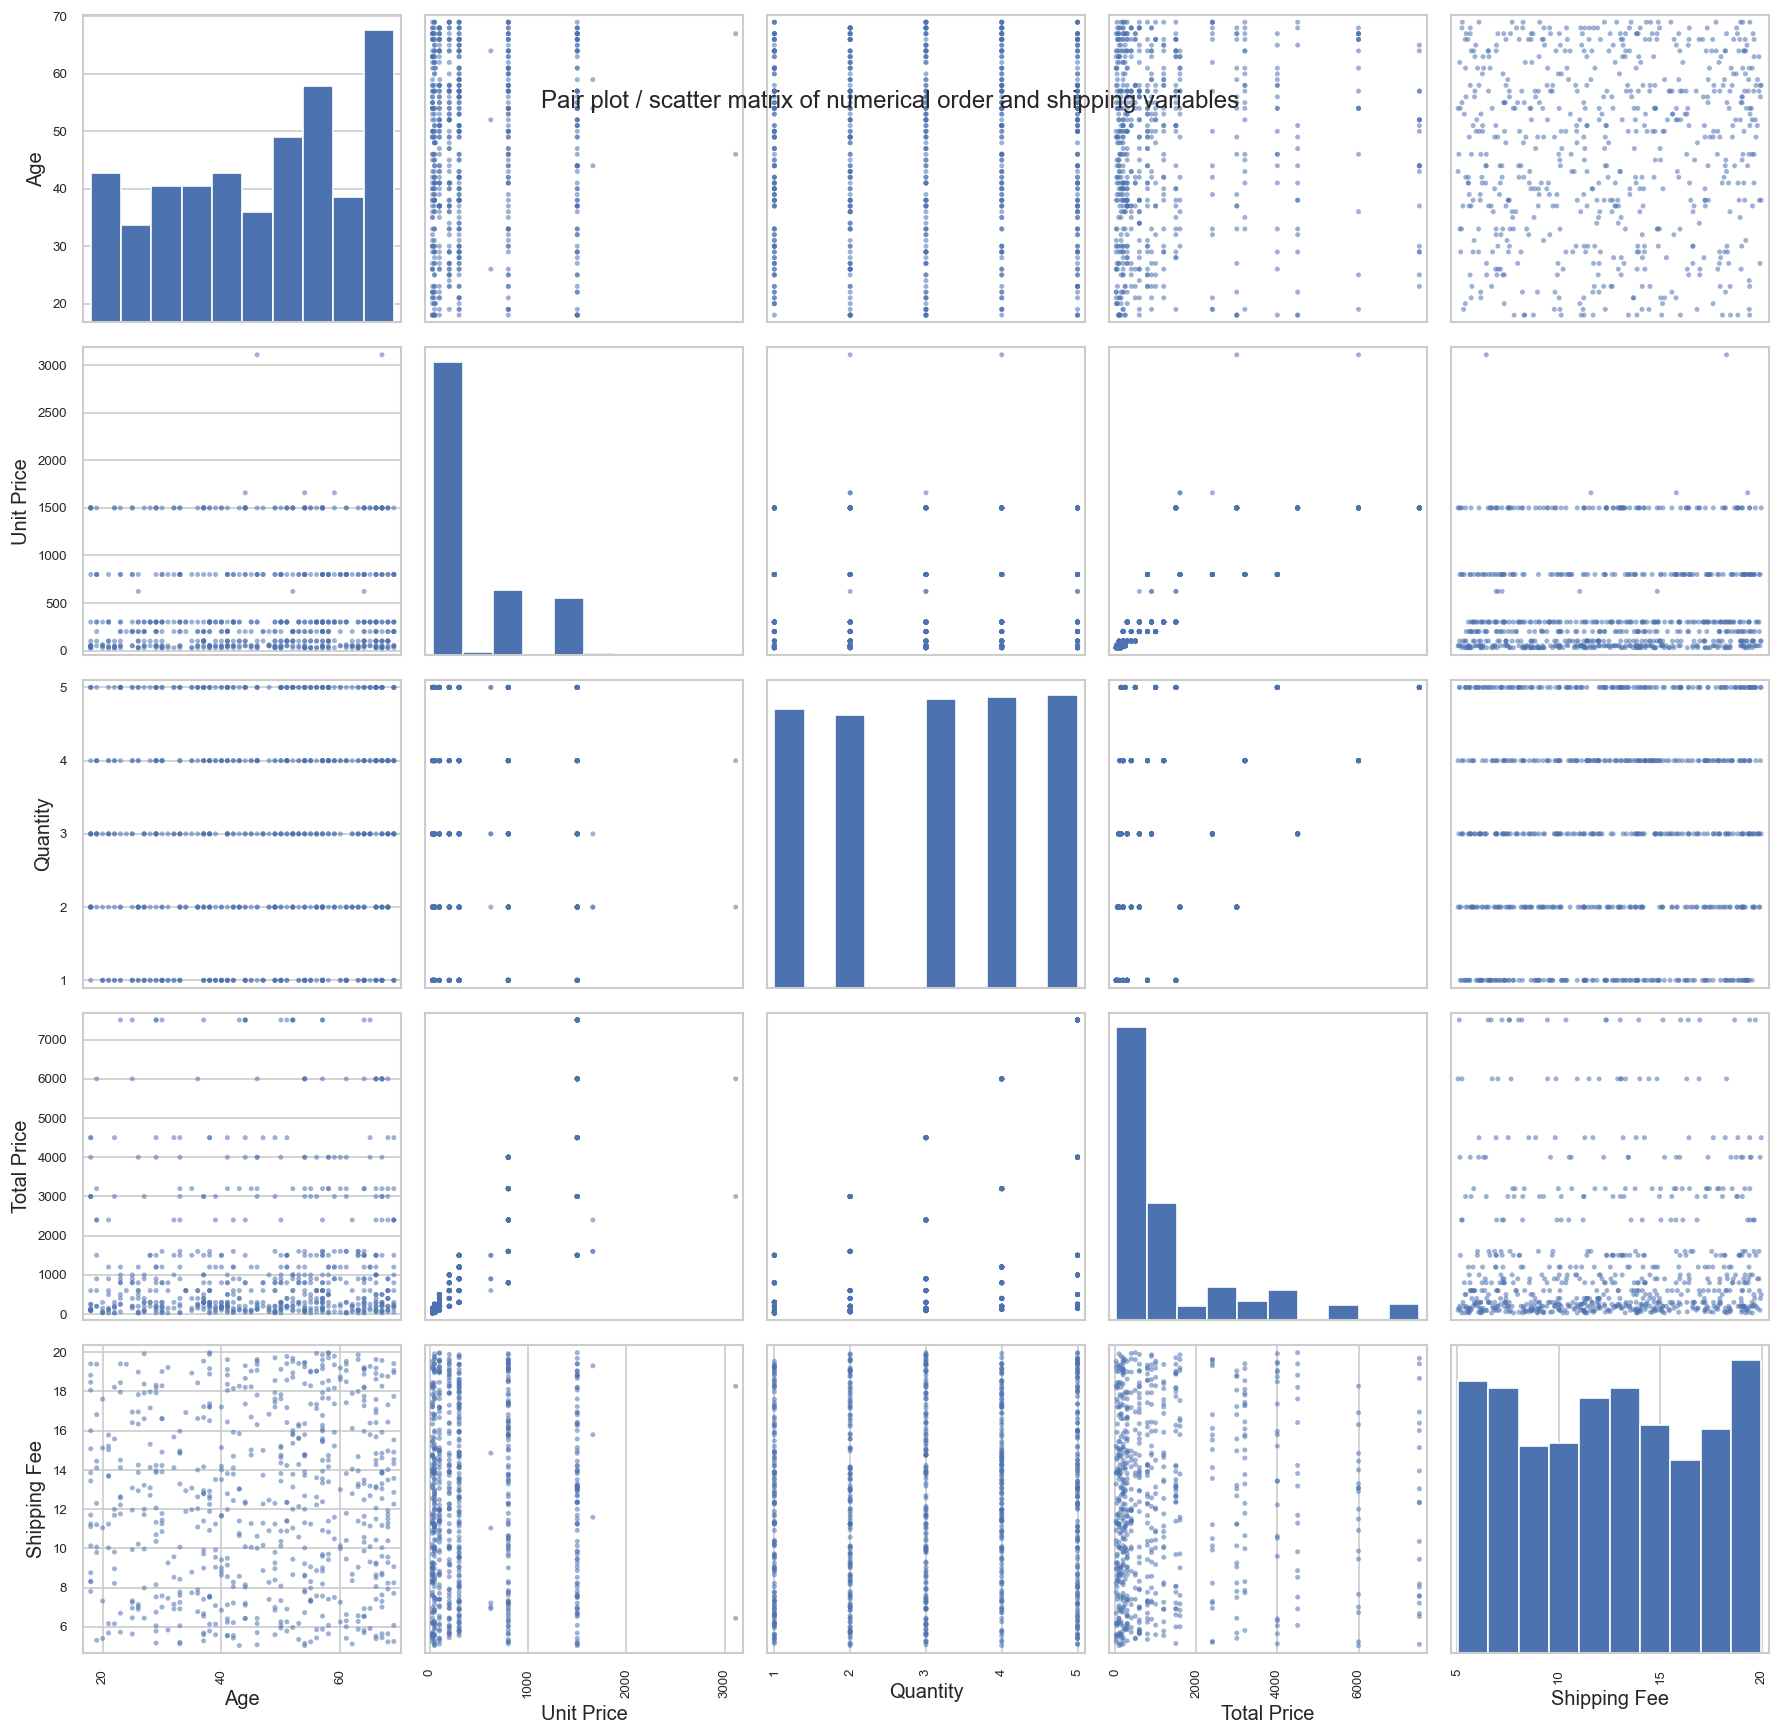

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/14_pairplot_numerical_variables.png


In [25]:
# Pair plot / scatter matrix using pandas for compatibility
from pandas.plotting import scatter_matrix

pair_cols = ["Age", "Unit Price", "Quantity", "Total Price", TARGET]
pair_sample = df[pair_cols].sample(min(700, len(df)), random_state=42)

axes = scatter_matrix(
    pair_sample,
    figsize=(15, 15),
    diagonal="hist",
    alpha=0.55
)
plt.suptitle("Pair plot / scatter matrix of numerical order and shipping variables", y=0.92)
plt.tight_layout()
plt.savefig(PLOT_DIR / "14_pairplot_numerical_variables.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {PLOT_DIR / '14_pairplot_numerical_variables.png'}")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/15_parallel_coordinates.png


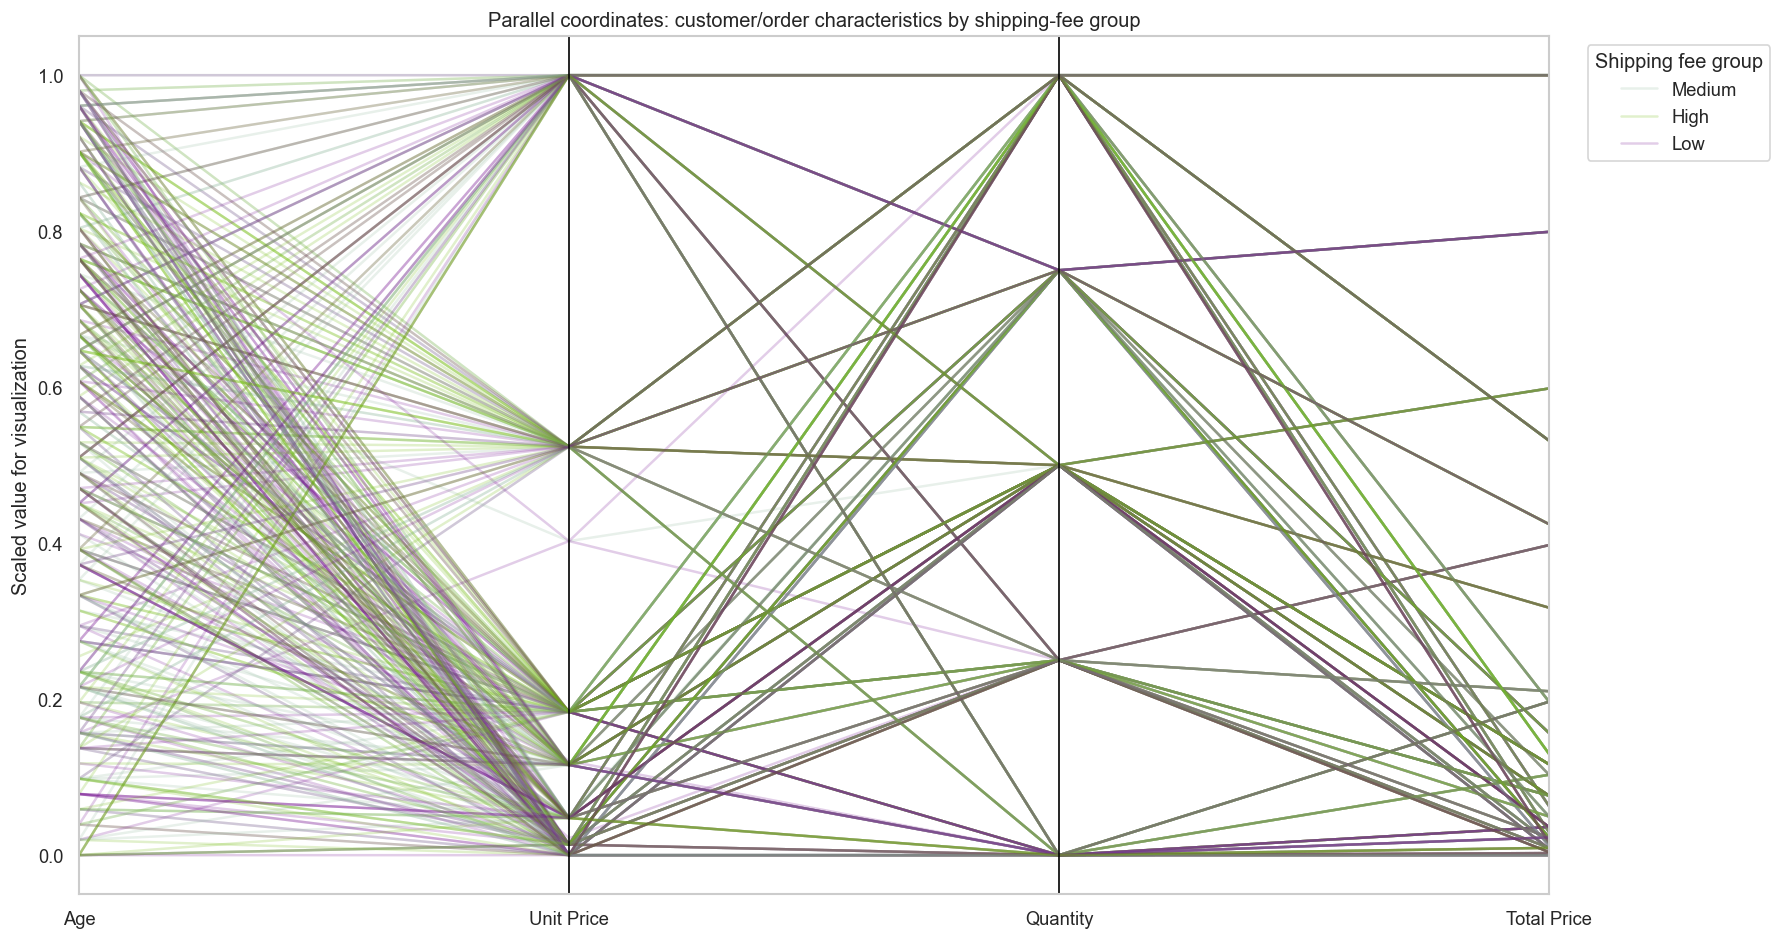

In [26]:
# Parallel coordinates using normalized order variables
pc_cols = ["Age", "Unit Price", "Quantity", "Total Price", TARGET]
pc = df[pc_cols].dropna().sample(min(500, len(df.dropna())), random_state=42).copy()

# Bin shipping fee into three descriptive levels for parallel-coordinate grouping
pc["Shipping_Fee_Group"] = pd.qcut(
    pc[TARGET], q=3, labels=["Low", "Medium", "High"], duplicates="drop"
)

for col in pc_cols:
    lo, hi = pc[col].quantile(0.01), pc[col].quantile(0.99)
    pc[col] = pc[col].clip(lo, hi)
    if pc[col].max() != pc[col].min():
        pc[col] = (pc[col] - pc[col].min()) / (pc[col].max() - pc[col].min())

plt.figure(figsize=(15, 8))
parallel_coordinates(pc.drop(columns=[TARGET]), "Shipping_Fee_Group", alpha=0.20)
plt.ylabel("Scaled value for visualization")
plt.title("Parallel coordinates: customer/order characteristics by shipping-fee group")
plt.legend(title="Shipping fee group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_save("15_parallel_coordinates")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/16_bubble_unit_price_quantity_total_price.png


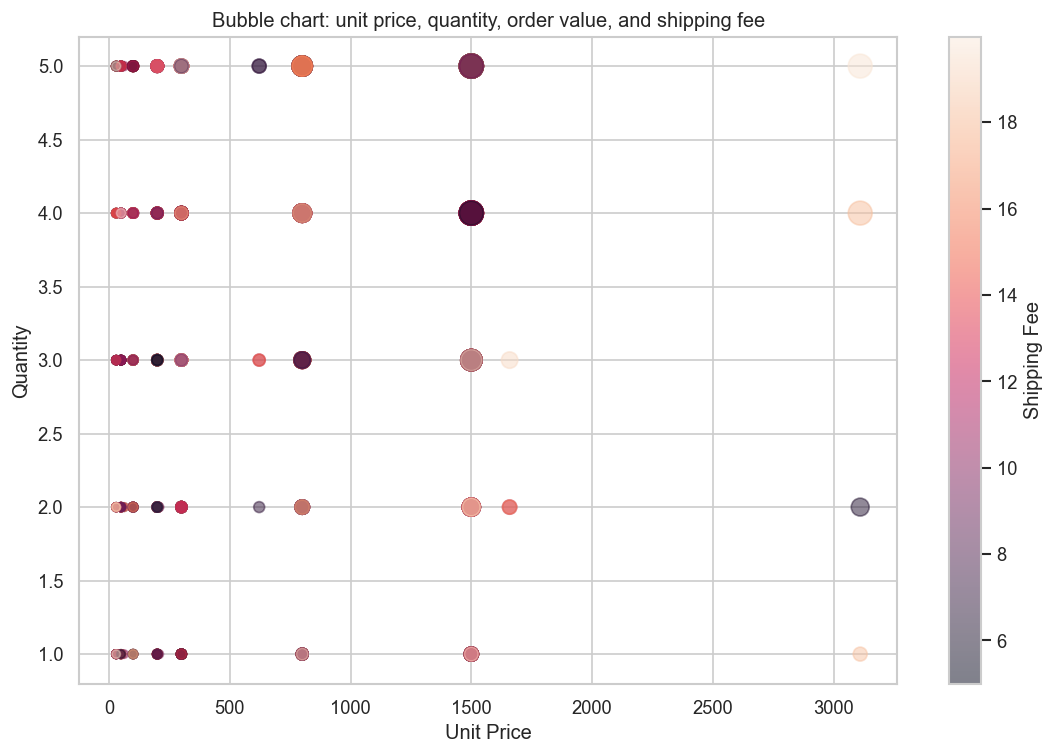

In [27]:
# Bubble chart: unit price vs quantity; bubble size = total price; colour = shipping fee
bubble = df[["Unit Price", "Quantity", "Total Price", TARGET]].dropna().copy()

sizes = 25 + 180*(bubble["Total Price"] / bubble["Total Price"].quantile(0.95)).clip(0, 1)

plt.figure(figsize=(11, 7))
sc = plt.scatter(
    bubble["Unit Price"],
    bubble["Quantity"],
    s=sizes,
    c=bubble[TARGET],
    alpha=0.50
)
plt.colorbar(sc, label="Shipping Fee")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.title("Bubble chart: unit price, quantity, order value, and shipping fee")
show_save("16_bubble_unit_price_quantity_total_price")


## 12. Relationships by categorical variables

Category, product, region, and gender can be examined using both average shipping fee and distributional plots.

The mean is useful for comparison, while the box/violin views show within-group variation.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/17_shipping_fee_boxplot_by_category.png


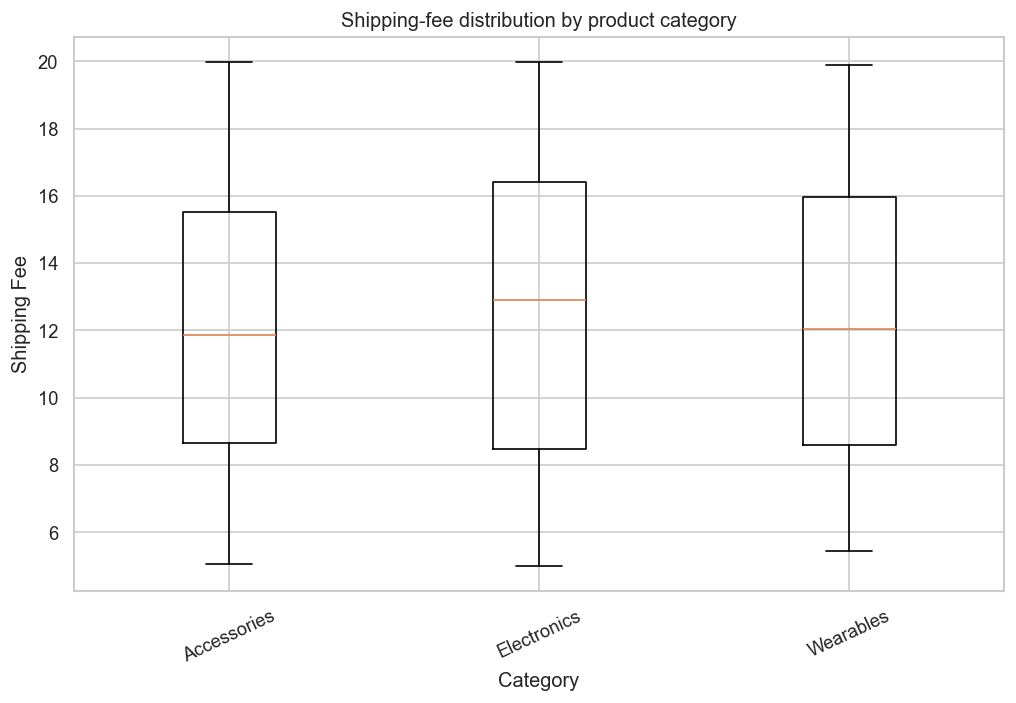

In [28]:
# Shipping fee by category — box plot
groups = []
labels = []
for label, group in df.groupby("Category", dropna=False):
    groups.append(group[TARGET].dropna().to_numpy())
    labels.append(str(label))

plt.figure(figsize=(10, 6))
plt.boxplot(groups, labels=labels)
plt.xlabel("Category")
plt.ylabel("Shipping Fee")
plt.title("Shipping-fee distribution by product category")
plt.xticks(rotation=25)
show_save("17_shipping_fee_boxplot_by_category")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/18_shipping_fee_boxplot_by_region.png


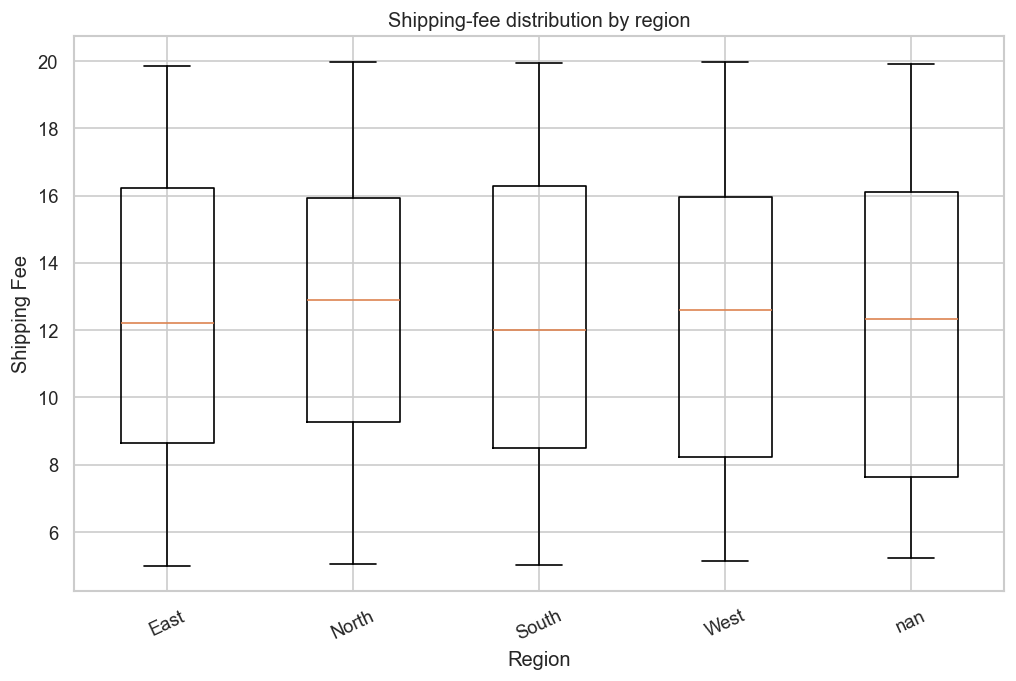

In [29]:
# Shipping fee by region — box plot
groups = []
labels = []
for label, group in df.groupby("Region", dropna=False):
    groups.append(group[TARGET].dropna().to_numpy())
    labels.append(str(label))

plt.figure(figsize=(10, 6))
plt.boxplot(groups, labels=labels)
plt.xlabel("Region")
plt.ylabel("Shipping Fee")
plt.title("Shipping-fee distribution by region")
plt.xticks(rotation=25)
show_save("18_shipping_fee_boxplot_by_region")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/19_mean_shipping_fee_by_product.png


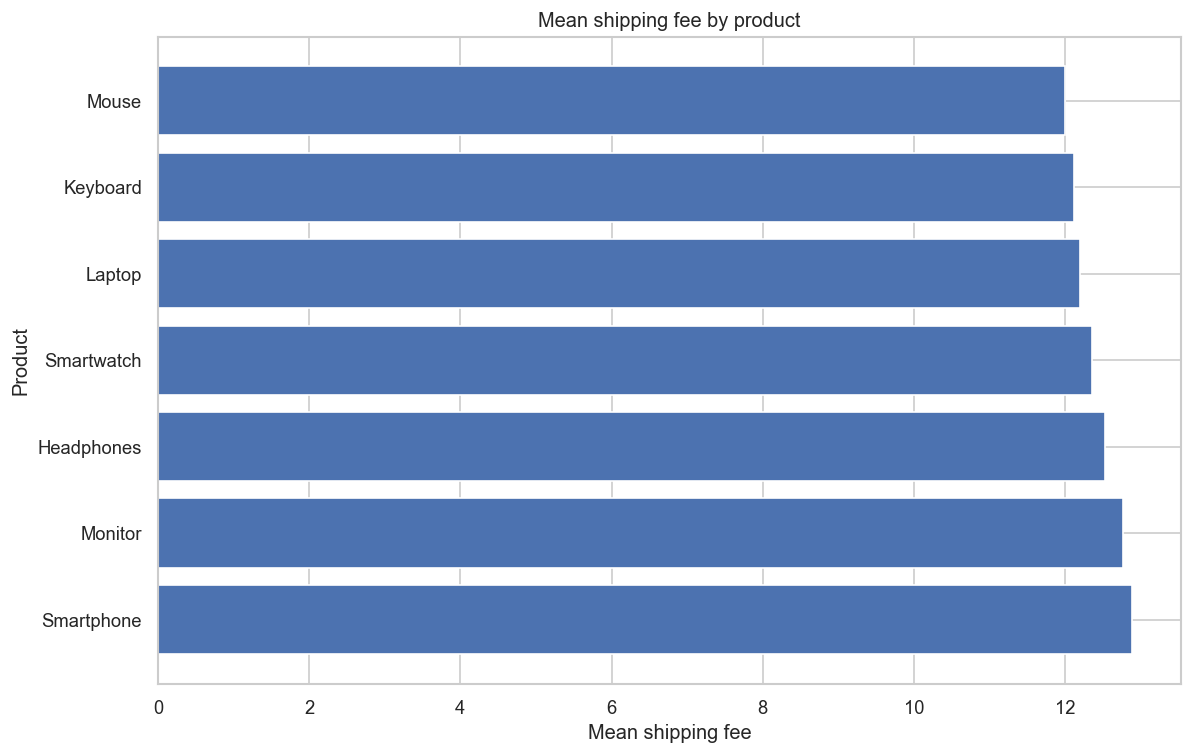

In [30]:
# Product-level mean shipping fee
product_fee = df.groupby("Product Name")[TARGET].mean().sort_values(ascending=False)

plt.figure(figsize=(11, 7))
plt.barh(product_fee.index, product_fee.values)
plt.xlabel("Mean shipping fee")
plt.ylabel("Product")
plt.title("Mean shipping fee by product")
show_save("19_mean_shipping_fee_by_product")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/20_category_region_shipping_fee_heatmap.png


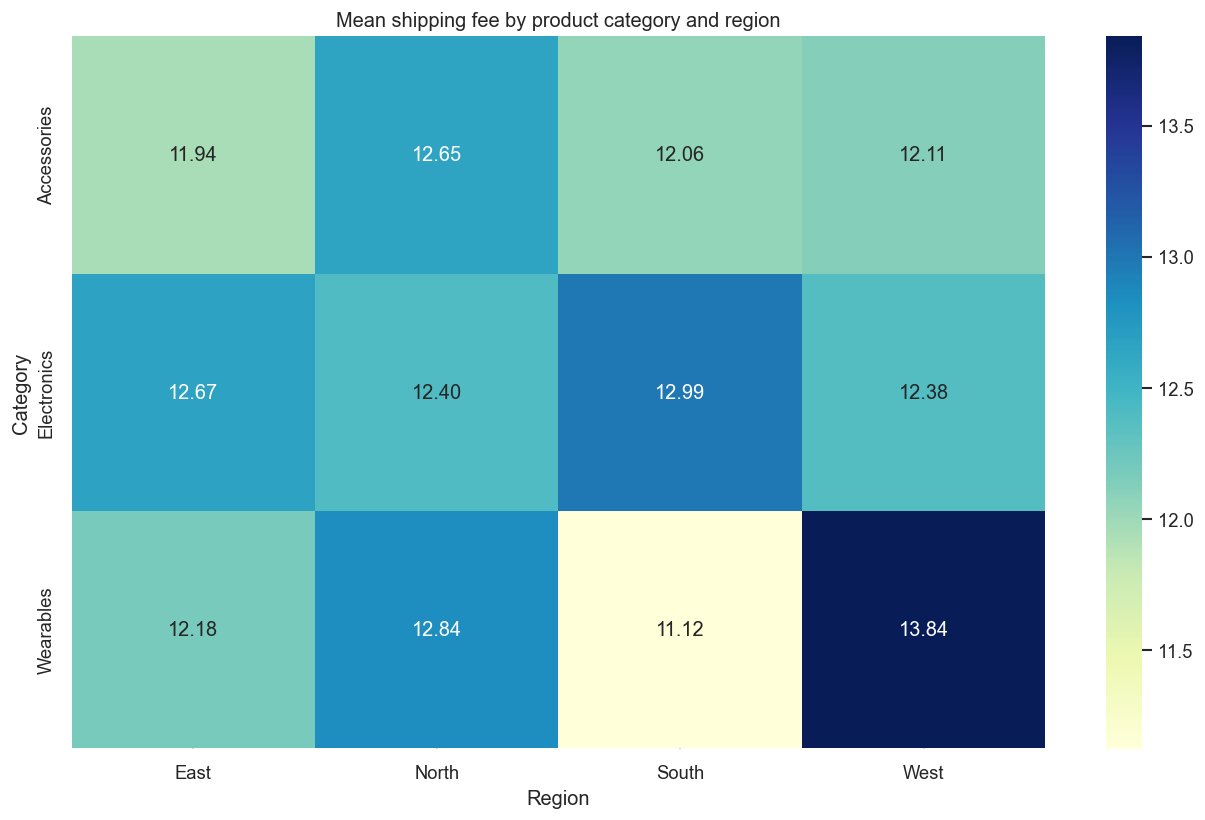

In [31]:
# Category x region heatmap of mean shipping fee
category_region = pd.pivot_table(
    df, values=TARGET, index="Category", columns="Region", aggfunc="mean"
)

plt.figure(figsize=(11, 7))
sns.heatmap(category_region, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Mean shipping fee by product category and region")
plt.tight_layout()
show_save("20_category_region_shipping_fee_heatmap")


# Part F — Order characteristics and temporal relationships

## 13. Quantity and order value

Because `Total Price` is exactly `Unit Price × Quantity`, the relationship between order value and shipping fee can be examined without treating `Total Price` as an independent physical measurement.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/21_shipping_fee_vs_total_price_category.png


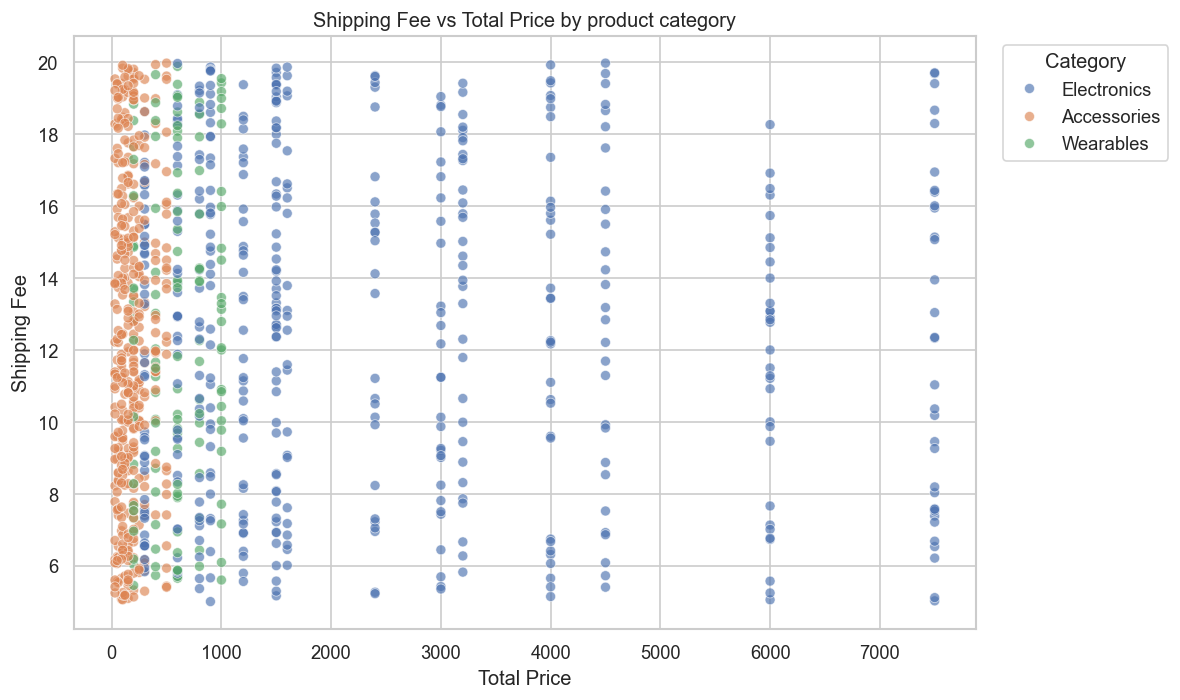

In [32]:
# Shipping fee vs total price
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Total Price", y=TARGET, hue="Category", alpha=0.65)
plt.title("Shipping Fee vs Total Price by product category")
plt.xlabel("Total Price")
plt.ylabel("Shipping Fee")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_save("21_shipping_fee_vs_total_price_category")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/22_shipping_fee_by_quantity.png


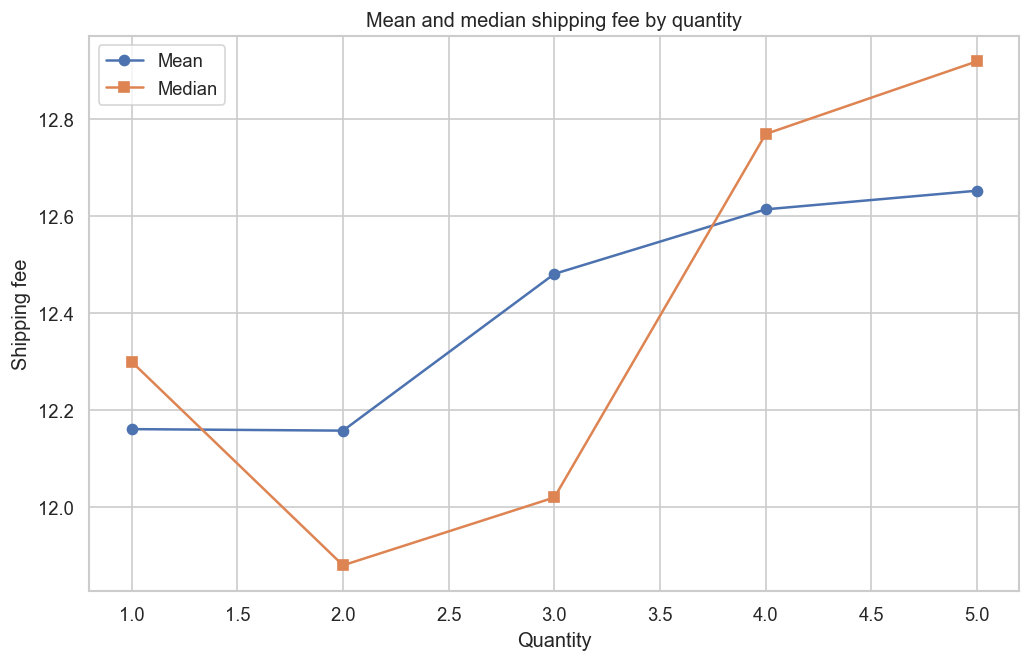

In [33]:
# Shipping fee vs quantity
quantity_fee = df.groupby("Quantity")[TARGET].agg(["mean", "median", "count"])

plt.figure(figsize=(10, 6))
plt.plot(quantity_fee.index, quantity_fee["mean"], marker="o", label="Mean")
plt.plot(quantity_fee.index, quantity_fee["median"], marker="s", label="Median")
plt.xlabel("Quantity")
plt.ylabel("Shipping fee")
plt.title("Mean and median shipping fee by quantity")
plt.legend()
show_save("22_shipping_fee_by_quantity")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/23_shipping_fee_vs_unit_price_category.png


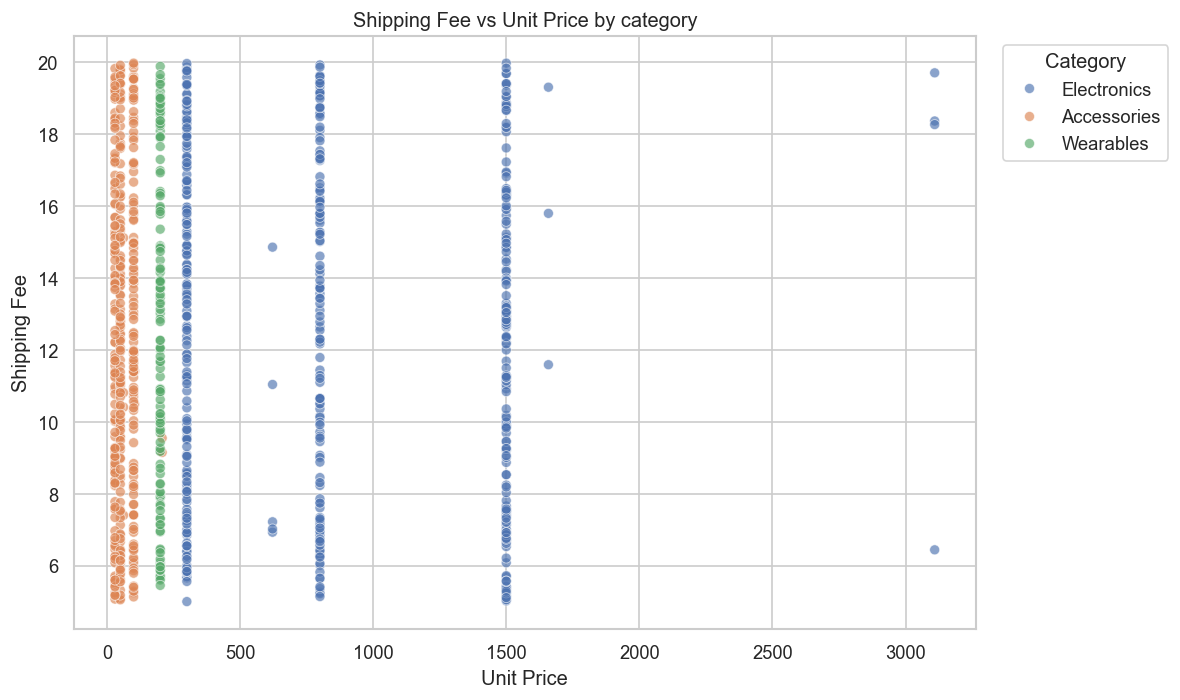

In [34]:
# Shipping fee vs unit price
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Unit Price", y=TARGET, hue="Category", alpha=0.65)
plt.title("Shipping Fee vs Unit Price by category")
plt.xlabel("Unit Price")
plt.ylabel("Shipping Fee")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_save("23_shipping_fee_vs_unit_price_category")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/24_monthly_mean_shipping_fee.png


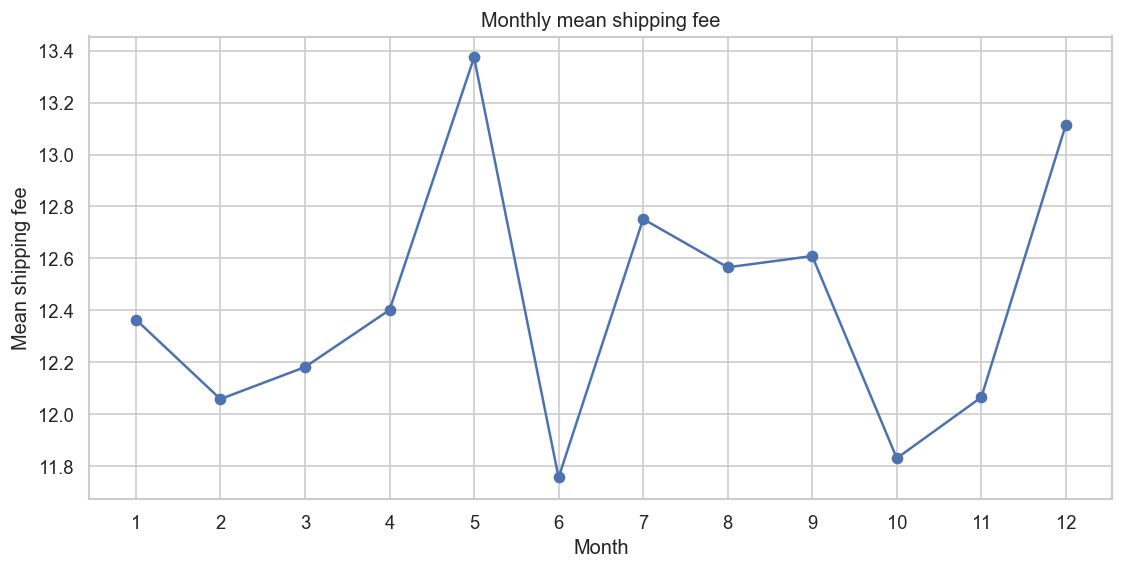

In [35]:
# Temporal features
df["Month"] = df["Order Date Parsed"].dt.month
df["Month_Name"] = df["Order Date Parsed"].dt.strftime("%b")
df["Day_of_Week"] = df["Order Date Parsed"].dt.day_name()

monthly_fee = df.groupby("Month")[TARGET].agg(["mean", "median", "count"])

plt.figure(figsize=(11, 5))
plt.plot(monthly_fee.index, monthly_fee["mean"], marker="o")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Mean shipping fee")
plt.title("Monthly mean shipping fee")
show_save("24_monthly_mean_shipping_fee")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/25_weekday_mean_shipping_fee.png


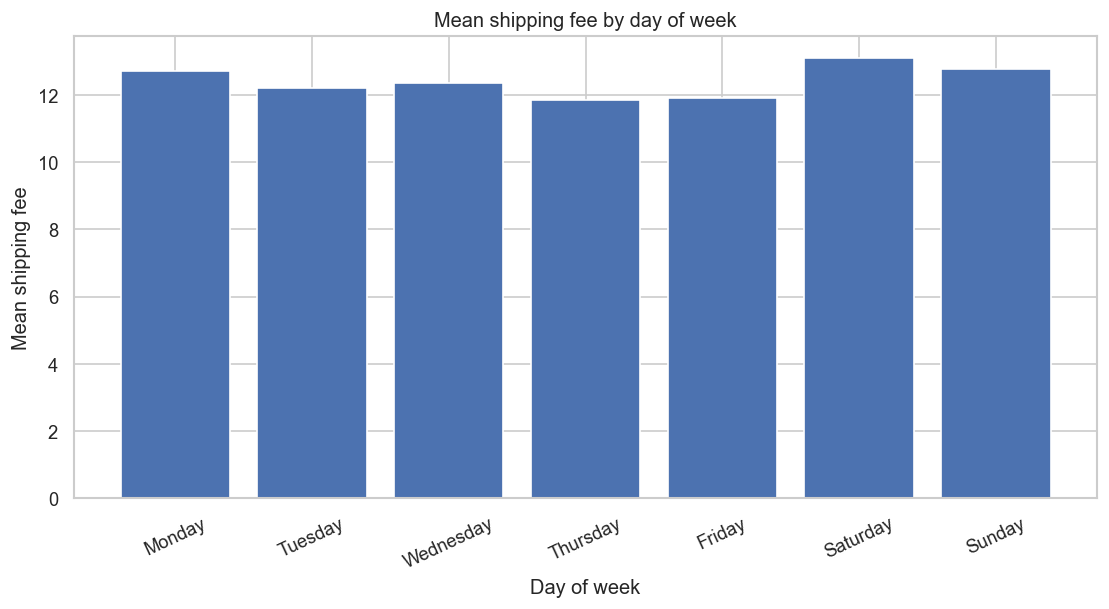

In [36]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_fee = df.groupby("Day_of_Week")[TARGET].mean().reindex(weekday_order)

plt.figure(figsize=(11, 5))
plt.bar(weekday_fee.index, weekday_fee.values)
plt.xticks(rotation=25)
plt.ylabel("Mean shipping fee")
plt.xlabel("Day of week")
plt.title("Mean shipping fee by day of week")
show_save("25_weekday_mean_shipping_fee")


# Part G — Customer insights

## 14. Customer-level descriptive analysis

`Customer ID` is an identifier. It can be useful for understanding repeat-customer behavior, but it should not be interpreted as a continuous predictor.

The following analysis examines:
- number of orders per customer;
- customer-level average shipping fee;
- customer age/gender context where available.


In [37]:
customer_summary = df.groupby("Customer ID").agg(
    Orders=("Customer ID", "size"),
    Mean_Shipping_Fee=(TARGET, "mean"),
    Mean_Order_Value=("Total Price", "mean"),
    Mean_Quantity=("Quantity", "mean"),
    Mean_Age=("Age", "mean")
).sort_values("Orders", ascending=False)

display(customer_summary.head(15))


,Orders,Mean_Shipping_Fee,Mean_Order_Value,Mean_Quantity,Mean_Age
Customer ID,,,,,
CUST0052,9,13.447778,651.111111,3.222222,66.0
CUST0204,9,11.282222,3233.333333,3.666667,54.0
CUST0044,9,14.735556,505.555556,2.666667,30.0
CUST0095,9,14.633333,2493.333333,3.777778,60.0
CUST0201,8,11.053750,1057.500000,2.000000,49.0
CUST0281,8,11.316250,2231.250000,3.125000,44.0
CUST0131,8,12.696250,2647.500000,3.000000,67.0
CUST0142,7,10.248571,735.714286,2.142857,32.0
CUST0064,7,11.604286,2085.714286,2.428571,61.0


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-4/26_customer_frequency_vs_mean_shipping_fee.png


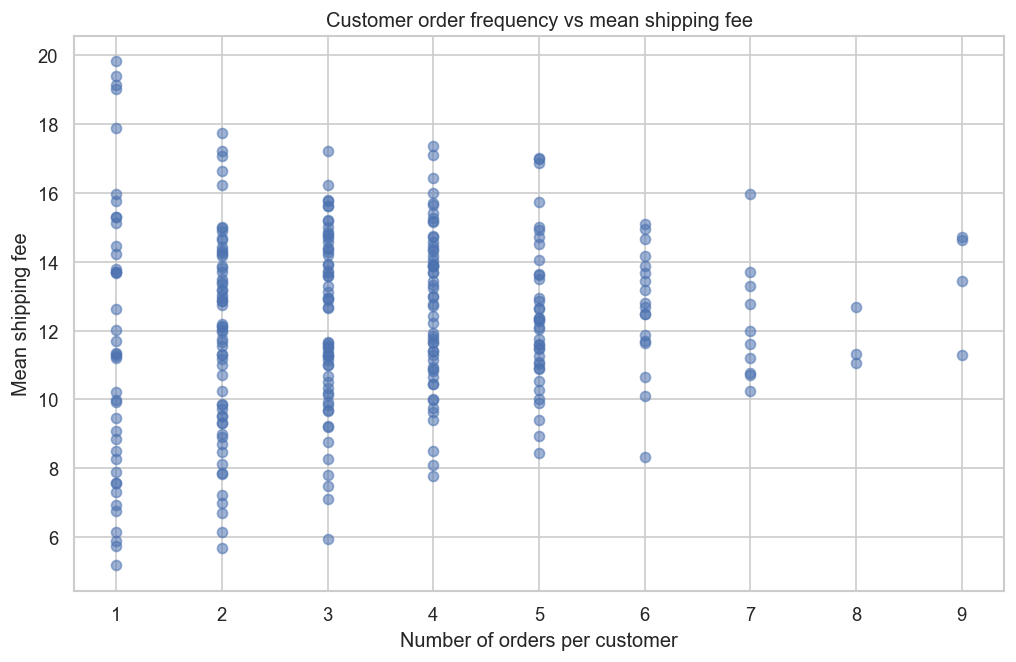

In [38]:
# Relationship between order frequency and mean shipping fee
customer_plot = customer_summary[customer_summary["Orders"] >= 1]

plt.figure(figsize=(10, 6))
plt.scatter(customer_plot["Orders"], customer_plot["Mean_Shipping_Fee"], alpha=0.55)
plt.xlabel("Number of orders per customer")
plt.ylabel("Mean shipping fee")
plt.title("Customer order frequency vs mean shipping fee")
show_save("26_customer_frequency_vs_mean_shipping_fee")


# Part H — Statistical relationship checks

## 15. Non-parametric group comparison

Shipping fee may not be normally distributed, so a Mann–Whitney U test is used for two-group comparisons such as gender. For multiple categories, descriptive group statistics remain the primary EDA tool.

These tests are exploratory and should not be interpreted as causal evidence.


In [39]:
# Mann–Whitney U: shipping fee by gender
gender_groups = [
    df.loc[df["Gender"] == g, TARGET].dropna()
    for g in df["Gender"].dropna().unique()
]

if len(gender_groups) == 2:
    g_labels = list(df["Gender"].dropna().unique())
    u_stat, p_value = stats.mannwhitneyu(
        gender_groups[0], gender_groups[1], alternative="two-sided"
    )
    print("Gender groups:", g_labels)
    print("Mann–Whitney U statistic:", u_stat)
    print("p-value:", p_value)
else:
    print("Gender does not contain exactly two non-null groups; no two-group Mann–Whitney test performed.")


Gender groups: ['Male', 'Female']
Mann–Whitney U statistic: 124773.5
p-value: 0.9893300598958656


In [40]:
# Spearman correlations with shipping fee
spearman_records = []
for col in numeric_predictors:
    valid = df[[col, TARGET]].dropna()
    rho, p = stats.spearmanr(valid[col], valid[TARGET])
    spearman_records.append({
        "Feature": col,
        "Spearman_rho": rho,
        "p_value": p
    })

spearman_table = pd.DataFrame(spearman_records).sort_values(
    "Spearman_rho", key=lambda s: s.abs(), ascending=False
)
display(spearman_table.round(4))


,Feature,Spearman_rho,p_value
3,Total Price,0.0546,0.0845
2,Quantity,0.0467,0.1403
1,Unit Price,0.0362,0.2521
0,Age,0.0255,0.4448


# Part I — Brainstorming

## 16. Evidence-based findings, hypotheses, and questions

The brainstorming section separates:

- **Finding:** directly observed in the supplied data;
- **Hypothesis:** a testable interpretation;
- **Question:** a point for subsequent modeling/domain investigation.

Each point references the relevant figure or statistical table.


In [41]:
# Build compact evidence facts for cross-referencing
mean_fee_by_category = df.groupby("Category")[TARGET].mean().sort_values(ascending=False)
mean_fee_by_region = df.groupby("Region", dropna=False)[TARGET].mean().sort_values(ascending=False)
mean_fee_by_quantity = df.groupby("Quantity")[TARGET].mean().sort_values(ascending=False)

print("Highest mean-fee category:", mean_fee_by_category.index[0], mean_fee_by_category.iloc[0])
print("Lowest mean-fee category:", mean_fee_by_category.index[-1], mean_fee_by_category.iloc[-1])
print("Highest mean-fee region:", mean_fee_by_region.index[0], mean_fee_by_region.iloc[0])
print("Quantity with highest observed mean fee:", mean_fee_by_quantity.index[0], mean_fee_by_quantity.iloc[0])


Highest mean-fee category: Electronics 12.615765199161427
Lowest mean-fee category: Accessories 12.198279301745636
Highest mean-fee region: North 12.548515283842795
Quantity with highest observed mean fee: 5 12.652994923857868


### Brainstorming 1 — Product category may influence shipping fee

**Finding:** Mean shipping fees differ across product categories (Figure 6), and their distributions can also differ (Figure 17).

**Hypothesis:** Product category may act as a proxy for physical characteristics such as size, weight, packaging requirements, or handling complexity.

**Question:** Does category remain informative after accounting for unit price and quantity?

**Modeling implication:** Category should be retained as a categorical candidate feature, with appropriate encoding in the later modeling stage.


### Brainstorming 2 — Unit price and shipping fee may be associated, but price is not necessarily shipping cost

**Finding:** `Unit Price` has an observable relationship with `Shipping Fee` in the correlation matrix and scatter plot (Figures 13 and 23).

**Hypothesis:** Higher-priced products may be associated with higher shipping fees if price is correlated with product size/value or packaging requirements.

**Question:** Is the relationship caused by product characteristics represented by `Category` and `Product Name`, rather than by monetary value itself?

**Important distinction:** Unit price is not a direct measure of physical shipping cost, so the relationship should not automatically be interpreted causally.


### Brainstorming 3 — Quantity may have a nonlinear effect

**Finding:** Shipping fee changes across different order quantities (Figure 22), while quantity also enters directly into `Total Price`.

**Hypothesis:** Shipping fee may increase with quantity, but possibly with diminishing returns if multiple units can be consolidated into the same shipment.

**Question:** Does the marginal shipping fee for additional units decline at higher quantities?

**Follow-up:** Later regression models should compare linear quantity effects with nonlinear transformations or tree-based models.


### Brainstorming 4 — `Total Price` is useful but redundant

**Finding:** The leakage audit establishes that `Total Price = Unit Price × Quantity` for the supplied data.

**Hypothesis:** Total order value may correlate with shipping fee because larger orders can involve different packaging or shipping arrangements.

**Question:** Does `Total Price` add information beyond `Unit Price` and `Quantity`?

**Modeling implication:** Compare feature specifications rather than automatically including all three variables. This is a multicollinearity/redundancy question, not a target-leakage problem.


### Brainstorming 5 — Region may capture shipping-zone differences

**Finding:** Mean shipping fees differ by region (Figure 7), and the category-by-region heatmap shows joint differences (Figure 20).

**Hypothesis:** Region may represent differences in shipping distance, fulfillment coverage, or delivery-zone pricing.

**Question:** Are regional differences stable across product categories, or do some categories show much larger regional variation?

**Follow-up:** The interaction between `Region` and `Category` should be considered in later modeling.


### Brainstorming 6 — Customer age and gender may show weak or indirect relationships

**Finding:** Age and gender distributions and their shipping-fee comparisons are shown in Figures 8, 11, and the categorical summaries.

**Hypothesis:** Customer demographics may have little direct influence on shipping fee but could correlate indirectly with product/category or order-size choices.

**Question:** Do demographic variables retain useful information after category, quantity, unit price, and region are considered?

**Caution:** Demographic associations should be interpreted carefully and should not be treated as evidence that customer characteristics cause shipping costs.


### Brainstorming 7 — Order timing may capture business or operational variation

**Finding:** The supplied `Order Date` spans 2023 and supports monthly and weekday comparisons (Figures 24–25).

**Hypothesis:** Shipping fees may vary over time because product mix, promotions, demand, or operational policies vary across periods.

**Question:** Are temporal differences genuine pricing effects, or are they explained by changing product/category/region composition?

**Follow-up:** Temporal variables should be validated for out-of-sample use because future-period prediction requires careful time-based validation.


### Brainstorming 8 — Product name may contain information beyond category

**Finding:** Multiple product names exist within categories, and product-level mean shipping fees vary (Figure 19).

**Hypothesis:** Product name may capture product-specific characteristics that broad category labels do not capture.

**Question:** Does product name improve prediction after category, price, quantity, and region are included?

**Caution:** Product-level features can overfit when rare products have few observations. Frequency and sample-size checks should therefore be performed before final modeling.


### Brainstorming 9 — Outliers may represent meaningful high-value orders

**Finding:** The IQR analysis identifies unusual observations in variables such as price, quantity, total order value, and shipping fee (Figures 10–12).

**Hypothesis:** Some outliers may represent legitimate large or high-value orders rather than data errors.

**Question:** Are extreme shipping fees associated with particular categories, quantities, or regions?

**Follow-up:** Later analysis should compare robust and ordinary regression approaches instead of deleting all outliers automatically.


### Brainstorming 10 — Fulfillment status should not be used as a pre-shipping predictor

**Finding:** `Shipping Status` contains post-order fulfillment information and has missing values (Figure 4).

**Hypothesis:** Fulfillment status may become known only after the shipping process begins, so using it to predict the initial shipping fee could violate the intended prediction-time information set.

**Question:** At what precise business-process point is `Shipping Fee` determined?

**Decision:** `Shipping Status` is retained for descriptive data-quality inspection but excluded from the primary pre-shipping feature set.


# Part J — Final EDA conclusion

## 17. Overall analytical picture

The supplied dataset is a **1,000-row e-commerce order dataset with 12 original columns**. It combines:

- customer information,
- geographic region,
- product/category information,
- unit price,
- quantity,
- total merchandise value,
- shipping fee,
- fulfillment status,
- order date.

### Primary target

**`Shipping Fee`** — continuous numerical outcome.

### Primary relevant predictors

- `Category`
- `Product Name`
- `Unit Price`
- `Quantity`
- `Region`
- `Gender`
- `Age`
- `Total Price`
- `Order Date`-derived temporal features

### Excluded from primary prediction

- `Customer ID` as a raw identifier
- `Shipping Status` as a fulfillment/post-order variable

### `Total Price` decision

The explicit audit confirms that:

**`Total Price = Unit Price × Quantity`**

for the supplied data. Therefore, it does **not** directly embed `Shipping Fee`. It is retained for EDA but should be treated as redundant with its components during later model development.

### Main questions for the next stage

1. How strongly does product category explain shipping-fee differences?
2. Does region capture meaningful shipping-zone variation?
3. Does quantity have a nonlinear or diminishing-return relationship with shipping fee?
4. Does total order value add information beyond unit price and quantity?
5. Does product name contain useful product-specific information beyond category?
6. Are demographic relationships stable after accounting for order characteristics?
7. Do temporal patterns generalize to future orders?
8. Which outliers are legitimate high-value orders?
9. Which feature set produces the best out-of-sample shipping-fee prediction without information leakage?

No observations are silently deleted or imputed in this EDA. Those decisions belong to the subsequent modeling stage and should be justified using a leakage-safe preprocessing workflow.


# 18. External methodological references

The following external sources support the methodological framing of the EDA and later modeling workflow:

1. **NIST/SEMATECH e-Handbook of Statistical Methods — Exploratory Data Analysis**  
   https://www.itl.nist.gov/div898/handbook/eda/section1/eda11.htm  
   Used for the general EDA principle of using graphical/statistical techniques to understand distributions, relationships, and unusual observations.

2. **NIST/SEMATECH — Detection of Outliers**  
   https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm  
   Used to support treating outliers as observations requiring investigation rather than automatic deletion.

3. **scikit-learn — Preprocessing data**  
   https://scikit-learn.org/stable/modules/preprocessing.html  
   Used for methodological context on scaling, categorical preprocessing, robust methods, and feature transformations.

4. **scikit-learn — Imputation of missing values**  
   https://scikit-learn.org/stable/modules/impute.html  
   Used for methodological context on missing-value handling.

5. **scikit-learn — Pipelines and composite estimators**  
   https://scikit-learn.org/stable/modules/compose.html  
   Used for the principle that preprocessing should be incorporated into a leakage-safe modeling workflow.

### Source limitation

These references support the **methodology**. They are not presented as the source of the supplied e-commerce dataset. The CSV itself does not document an original publisher or collection protocol, so no unsupported provenance claim is made.


In [42]:
# Final feature-role manifest for report cross-reference
feature_manifest = pd.DataFrame({
    "Column": [
        "Customer ID", "Gender", "Region", "Age", "Product Name", "Category",
        "Unit Price", "Quantity", "Total Price", "Shipping Fee",
        "Shipping Status", "Order Date"
    ],
    "Role": [
        "Identifier — descriptive only",
        "Retained predictor",
        "Retained predictor",
        "Retained predictor",
        "Retained predictor",
        "Retained predictor",
        "Retained predictor",
        "Retained predictor",
        "Retained after leakage audit; redundant with Unit Price × Quantity",
        "TARGET",
        "Excluded from primary pre-shipping predictor set",
        "Retained → derive temporal features"
    ]
})
display(feature_manifest)


,Column,Role
0,Customer ID,Identifier — descriptive only
1,Gender,Retained predictor
2,Region,Retained predictor
3,Age,Retained predictor
4,Product Name,Retained predictor
5,Category,Retained predictor
6,Unit Price,Retained predictor
7,Quantity,Retained predictor
8,Total Price,Retained after leakage audit; redundant with U...
9,Shipping Fee,TARGET
